In [1]:
'''
post-processing pipeline in order !!! maybe final version!!!
'''

'\npost-processing pipeline in order !!! maybe final version!!!\n'

In [1]:
import numpy as np
import pandas as pd
from astropy.io import fits
import matplotlib.pyplot as plt
import precision_recall as pr
import gc  # garbage collector
import review_findings_functions as rff
import os
import importlib
import implantation_functions as imp
import corner
plt.rcParams["figure.figsize"] = (10, 7)
plt.rcParams["image.interpolation"] = "nearest"
plt.rcParams["image.cmap"] = "gist_gray"

Matplotlib is building the font cache; this may take a moment.


In [ ]:
#remove the lightcurves first thing, then reject 1 pixel, edges, deduplication, SNR, sobel, moving objects manual, simultaneous

In [ ]:
#maybe count the number of pixels
#count the number before matching to streaks
#then count the number matching to all streaks
#then the number that gets cut out

In [62]:
concat = pd.read_csv('/lustre/lrspec/ZTF_data/science_extractions/1020april26/average/concat')

In [12]:
concat_band = pd.read_csv('/lustre/lrspec/ZTF_data/science_extractions/1020april26/average/concat_with_band')

In [158]:
concat_filtered = pd.read_csv('/lustre/lrspec/ZTF_data/science_extractions/1020april26/average/concat_filtered3') 
#have both 

In [2]:
concat_filtered_with_rf = pd.read_csv('/lustre/lrspec/ZTF_data/concat_filtered_denoised_rf')

In [3]:
rf_gone = concat_filtered_with_rf[concat_filtered_with_rf['random_forest_result']==0]

In [2]:
rf_gone = pd.read_csv('/lustre/lrspec/ZTF_data/science_extractions/1020april26/average/rf_gone_with_brightness_ranking')

In [3]:
rf_gone['concat_index_copy']=rf_gone['Unnamed: 0.3']

In [36]:
concat = pd.read_csv('/lustre/lrspec/ZTF_data/concat_filtered_denoised_rf')

In [37]:
concat

,Unnamed: 0.10,Unnamed: 0.9,Unnamed: 0.8,Unnamed: 0.7,Unnamed: 0.6,Unnamed: 0.5,Unnamed: 0.4,Unnamed: 0.3,Unnamed: 0.2,Unnamed: 0.1,...,central_point_brightening_denoise,snr_local_dimming_denoised,snr_global_dimming_denoised,noise_local_dimming_denoised,noise_global_dimming_denoised,local_average_outside_dimming_denoised,height_dimming_denoised,FWHM_dimming_denoised,signal_local_dimming_denoised,central_point_dimming_denoised
0,0,0,0,0,0,0,0,0,0,0,...,697.0,0.097634,0.119836,211.498252,172.313005,574.058211,-262.954360,2.0,20.649366,703.0
1,1,1,1,1,1,1,1,1,1,1,...,1175.0,0.163383,0.147859,157.519775,174.057900,547.898898,-252.161251,3.0,25.736019,1168.0
2,2,2,2,2,2,2,2,2,2,2,...,2087.0,0.044367,0.035578,136.544338,170.276620,600.103755,-36.699783,1.0,6.058035,2082.0
3,3,3,3,3,3,3,3,3,3,3,...,2467.0,0.088891,0.094558,181.918712,171.016256,603.029128,-164.977715,2.0,16.171015,2461.0
4,4,4,4,4,4,4,4,4,4,4,...,2572.0,0.193704,0.186482,164.263000,170.624386,640.590673,-508.411280,2.0,31.818422,2578.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
347419,347419,347419,347419,347419,347419,347419,347419,347419,347419,49,...,842.0,0.377792,0.407922,39.296771,36.394246,534.631243,-121.305341,2.0,14.846003,833.0
347420,347420,347420,347420,347420,347420,347420,347420,347420,347420,50,...,1262.0,0.918837,0.890739,15.552805,16.043402,539.791970,-61.009525,4.0,14.290490,1253.0
347421,347421,347421,347421,347421,347421,347421,347421,347421,347421,51,...,1357.0,0.308593,0.356043,18.691568,16.200569,535.486638,-33.270877,1.0,5.768091,1366.0
347422,347422,347422,347422,347422,347422,347422,347422,347422,347422,0,...,844.0,0.134408,0.120027,203.921280,228.355593,664.435376,-432.625514,2.0,27.408739,830.0


In [38]:
rf_gone = concat[concat['random_forest_result']==0]

In [5]:
np.sum(rf_gone['concat_index_copy'].values-rf_gone.index.values)

0

In [21]:
len(concat_filtered_with_rf)

347424

In [39]:
len(rf_gone)

342433

In [84]:
len(concat)

347424

In [201]:
concat_filtered_with_rf


,Unnamed: 0.9,Unnamed: 0.8,Unnamed: 0.7,Unnamed: 0.6,Unnamed: 0.5,Unnamed: 0.4,Unnamed: 0.3,Unnamed: 0.2,Unnamed: 0.1,Unnamed: 0,...,height_dimming_f3,FWHM_dimming_f3,signal_local_dimming_f3,central_point_dimming_f3,snr_local,snr_global,real_type_local,real_type_global,distance_from_start,random_forest_result
0,0,0,0,0,0,0,0,0,0,0,...,-356.194423,3.0,30.026146,690.0,0.120616,0.145088,pos,pos,138.500000,0.0
1,1,1,1,1,1,1,1,1,1,3,...,-472.117198,5.0,42.164851,1160.0,0.163725,0.148208,neg,neg,-338.312500,0.0
2,2,2,2,2,2,2,2,2,2,4,...,-117.115640,1.0,10.821998,2070.0,0.507125,0.409946,pos,pos,-1255.173913,0.0
3,3,3,3,3,3,3,3,3,3,6,...,-680.929089,6.0,54.227081,2461.0,0.190395,0.198984,pos,pos,-1632.625000,0.0
4,4,4,4,4,4,4,4,4,4,7,...,-279.760163,1.0,16.726032,2562.0,0.191027,0.187296,neg,neg,-1736.500000,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
347419,347419,347419,347419,347419,347419,347419,347419,347419,49,77,...,-198.335604,2.0,19.493971,833.0,0.377672,0.401030,neg,neg,625.500000,0.0
347420,347420,347420,347420,347420,347420,347420,347420,347420,50,34,...,-89.109350,3.0,13.851402,1253.0,0.918655,0.889413,neg,neg,-388.214286,0.0
347421,347421,347421,347421,347421,347421,347421,347421,347421,51,39,...,-34.856257,1.0,5.903919,1338.0,0.845833,0.911684,pos,pos,-491.156250,0.0
347422,347422,347422,347422,347422,347422,347422,347422,347422,0,0,...,-709.111444,3.0,41.629913,834.0,0.283822,0.246317,pos,pos,1227.142857,0.0


In [ ]:
#so right now we start with concat as _diffcut5_size1_dedup_snr
#lets not recalculate it for now

In [15]:
rf_gone['filename'].values[-4:]

array(['ztf_20221020157697_000640_zi_c05_x_0024.',
       'ztf_20221020157697_000640_zi_c05_x_0024.',
       'ztf_20221020294271_000449_zr_c04_x_0003.',
       'ztf_20221020157697_000640_zi_c11_x_0022.'], dtype=object)

In [6]:
to_keep_df = []
not_keep_df = []
for i, row in df.iterrows():
    # print(row['filename'][-5:])
    if row['filename'][-5:]!='0029.':
        to_keep_df.append(i)
    else:
        not_keep_df.append(i)
        

NameError: name 'df' is not defined

In [48]:
not_keep_df

[21, 27, 28, 29, 30, 51, 65, 73, 77]

In [40]:
to_keep = []
not_keep = []
for i, row in rf_gone.iterrows():
    # print(row['filename'][-5:])
    if row['filename'][-5:]!='0029.':
        to_keep.append(i)
    else:
        not_keep.append(i)
        

In [8]:
np.max(to_keep)

347423

In [5]:
len(to_keep)

325727

In [61]:
rf_gone['concat_index_copy']

KeyError: 'concat_index_copy'

In [41]:
rf_gone_no_0029 = rf_gone.loc[to_keep]

In [42]:
len(rf_gone_no_0029)

325727

In [9]:
def remove_starting_edges(concat): #first 100 pixels go bye bye #which turns into 90 cause 10 already gone
    df = concat.copy()
    # df["concat_index_copy"] = concat.index.values
    beginningstodrop = []
    for index in df.index.values:
        if df.loc[index, 'filename'][-5:]=='0000.':
            if df.loc[index,'quad']==1 or concat.loc[index,'quad']==2:
                if df.loc[index, 'row_from_nn']<90:
                    beginningstodrop.append(index)
            elif df.loc[index,'quad']==3 or concat.loc[index,'quad']==4:
                if df.loc[index, 'row_from_nn']+10 > 2979: #it was fine before but math is hard so im checking
                    beginningstodrop.append(index)
        if df.loc[index, 'row_from_nn']<10: #chop off first 20 pixels
            beginningstodrop.append(index)
        elif df.loc[index, 'col_from_nn']<10:
            beginningstodrop.append(index)
        elif df.loc[index, 'col_from_nn']>3041:
            beginningstodrop.append(index)
        elif df.loc[index, 'row_from_nn']>3049:
            beginningstodrop.append(index)
    df.drop(index=np.unique(beginningstodrop), inplace=True)
    return df#, beginningstodrop

In [209]:
np.max(rf_gone['col_from_nn'])

3051.0

In [43]:
nostartingedges = remove_starting_edges(rf_gone_no_0029)

In [11]:
len(rf_gone_no_0029)-len(nostartingedges)

8587

In [13]:
len(nostartingedges)

317140

In [193]:
def original_rows_to_array(original):
    # array = np.zeros((20,20))
    cleaned = original[1:-1]
    
    # Split into rows
    rows = []
    current_row = []
    
    # Split by brackets to identify rows
    parts = cleaned.strip().split(' ')
    # print(parts)
    real = []
    for part in parts:
        if part!='':
            correct = float(part)
            real.append(correct)
    
    real = np.array(real)
    
    return np.array(real)

In [39]:
for listy in concat_filtered.loc[beginningstodrop, 'original_rows_from_nn'].values:
    for el in original_rows_to_array(listy):
        if el>90:
            if el<2969:
                print(listy)


[81.30769231 90.82352941]
[2962.66666667 2978.8        2971.        ]
[2964.8 2993.5]
[2958.         2983.35294118 2976.        ]


In [105]:
len(nostartingedges)

333438

In [101]:
len(nostartingedges)

317140

In [46]:
# def count_real_snr(df):
#     for i, row in df.iterrows():
#         if row['snr_local_brightening']==np.NaN:
#             print("found one!")
# #just kidding...it appears that we calculated SNR for everything :0

In [51]:
local_or_global='local'
for i, row in nostartingedges.iterrows():
    if row['real_type_'+local_or_global]=='pos':
        nostartingedges.loc[i, 'snr_local_denoised'] = nostartingedges.loc[i, 'snr_local_brightening_denoised']
    else:
        nostartingedges.loc[i, 'snr_local_denoised'] = nostartingedges.loc[i, 'snr_local_dimming_denoised']


In [14]:
def remove_sobel(concat):
    df = concat.copy()
    brightening = pd.read_csv('/home/3155/sobel_ratios') #sobels for SNR>1 candidates
    droplist = brightening[brightening['sobel_ratiocentral_point_brightening5']<=2]['index_copy'].values
    # realdroplist = droplist[droplist in df.index.values]
    # realdroplist = []
    # for el in droplist:
    #     if el in df.index.values:
    #         realdroplist.append(el)
    
    # df.drop(index=np.unique(realdroplist), inplace=True)
    to_drop = []
    for i, row in df.iterrows():
        if row['concat_index_copy'] in droplist:
            to_drop.append(i)
    print('btw we already removed some of these: ',len(droplist)-len(to_drop))
    df.drop(to_drop, inplace=True)
    return df
    


In [52]:
nosobel = remove_sobel(nostartingedges)

btw we already removed some of these:  78


In [53]:
len(nostartingedges) - len(nosobel)

1167

In [129]:
satlist = np.load("/lustre/lrspec/ZTF_data/final_satlist.npy")
moresats = np.array([195365, 291022, 163685, 326045, 272956, 306621, 22579, 
            79095,262472, 293337, 298575, 154765,181844, 272947, 329013, 
                176927, 192302, 179370, 52316, 131777, 117765, 82320, 224886, 131780,
                         133395, 53727, 326040, 244374, 247862, 139635, 44003, 184032, 97098,
                        183186, 52301, 139053, 152177, 124943, 131763, 52319, 265520,
                    144297, 287498, 52302, 287496,287296
125688
269241
111169])#from filtered result
len(np.hstack((satlist, moresats)))


444

In [ ]:
#ones to take out



In [145]:
# rff.inspect_df_w_stamp_color(concat_filtered_with_rf.loc[np.hstack((satlist, moresats))][:100], 
#                              titlecol=['concat_index_copy'], imgsize=20)

In [144]:
# rff.inspect_df_w_stamp_color(concat_filtered_with_rf.loc[np.hstack((satlist, moresats))][100:200], 
#                              titlecol=['concat_index_copy'], imgsize=20)

In [143]:
# rff.inspect_df_w_stamp_color(concat_filtered_with_rf.loc[np.hstack((satlist, moresats))][200:300], 
#                              titlecol=['concat_index_copy'], imgsize=20)

In [142]:
# rff.inspect_df_w_stamp_color(concat_filtered_with_rf.loc[np.hstack((satlist, moresats))][300:400], 
#                              titlecol=['concat_index_copy'], imgsize=20)

In [141]:
# rff.inspect_df_w_stamp_color(concat_filtered_with_rf.loc[np.hstack((satlist, moresats))][400:-10], 
#                              titlecol=['concat_index_copy'], imgsize=20)

In [50]:
local_or_global='local'
for i, row in nosobel.iterrows():
    if row['real_type_'+local_or_global]=='pos':
        nosobel.loc[i, 'snr_local_denoised'] = nosobel.loc[i, 'snr_local_brightening_denoised']
    else:
        nosobel.loc[i, 'snr_local_denoised'] = nosobel.loc[i, 'snr_local_dimming_denoised']



KeyboardInterrupt



In [18]:
def remove_manual_sats(concat):
    satlist = np.load("/lustre/lrspec/ZTF_data/final_satlist.npy")
    moresats = np.array([195365, 291022, 163685, 326045, 272956, 306621, 22579, 
            79095,262472, 293337, 298575, 154765,181844, 272947, 329013, 
                176927, 192302, 179370, 52316, 131777, 117765, 82320, 224886, 131780,
                         133395, 53727, 326040, 244374, 247862, 139635, 44003, 184032, 97098,
                        183186, 52301, 139053, 152177, 124943, 131763, 52319, 265520,
                        144297, 287498, 52302, 287496, 151735, 262444, 1408])#from filtered result
    df = concat.copy()
    # realdroplist = droplist[droplist in df.index.values]
    # realdroplist = []
    # for el in np.hstack((satlist, moresats)):
    #     if el in df.index.values:
    #         realdroplist.append(el)
    # print('btw we already removed some of these: ',len(np.hstack((satlist, moresats)))-len(realdroplist))
    # df.drop(index=np.unique(realdroplist), inplace=True)
    
    realdroplist = []
    for el in np.hstack((satlist, moresats)):
        if el in df['concat_index_copy'].values:
            realdroplist.append(el)
    print('btw we already removed some of these: ',len(np.hstack((satlist, moresats)))-len(realdroplist))
    to_drop = []
    for i, row in df.iterrows():
        if row['concat_index_copy'] in realdroplist:
            if row['concat_index_copy'] not in [287296, 125688, 269241, 111169]: #questionable ones
                to_drop.append(i)
    df.drop(to_drop, inplace=True)
    return df

In [91]:
# np.save("/lustre/lrspec/ZTF_data/final_satlist.npy", np.array(final_satlist))
##double checked and they all look good
#rff.inspect_df_w_stamp_color(concat.loc[final_satlist][300:], titlecol=['concat_index_copy'], imgsize=20)

In [54]:
nosats = remove_manual_sats(nosobel)

btw we already removed some of these:  154


In [20]:
len(nosobel) - len(nosats)

288

In [21]:
len(nosats)

315685

In [49]:
nosobel.columns[50:]

Index(['height_brightening_filtered2', 'FWHM_brightening_filtered2',
       'signal_local_brightening_filtered',
       'central_point_brightening_filtere', 'snr_local_dimming_filtered2',
       'snr_global_dimming_filtered2', 'noise_local_dimming_filtered2',
       'noise_global_dimming_filtered', 'height_dimming_filtered2',
       'FWHM_dimming_filtered2', 'signal_local_dimming_filtered',
       'central_point_dimming_filtere', 'snr_local_brightening_f3',
       'snr_global_brightening_f3', 'noise_local_brightening_f3',
       'noise_global_brightening_f3', 'height_brightening_f3',
       'FWHM_brightening_f3', 'signal_local_brightening_f3',
       'central_point_brightening_f3', 'snr_local_dimming_f3',
       'snr_global_dimming_f3', 'noise_local_dimming_f3',
       'noise_global_dimming_f3', 'height_dimming_f3', 'FWHM_dimming_f3',
       'signal_local_dimming_f3', 'central_point_dimming_f3', 'snr_local',
       'snr_global', 'real_type_local', 'real_type_global',
       'distance_f

In [30]:
nosats['snr_local_brightening']

0         0.120616
1         0.139356
2         0.507125
3         0.190395
4         0.081756
            ...   
342428    0.344236
342429    0.523315
342430    0.845833
342431    0.283822
342432    0.727565
Name: snr_local_brightening, Length: 315685, dtype: float64

In [24]:
nosats['snr_local']

0         0.120616
1         0.163725
2         0.507125
3         0.190395
4         0.191027
            ...   
342428    0.377672
342429    0.918655
342430    0.845833
342431    0.283822
342432    0.727565
Name: snr_local, Length: 315685, dtype: float64

In [34]:
local_or_global='local'
for i, row in nosats.iterrows():
    if row['real_type_'+local_or_global]=='pos':
        nosats.loc[i, 'snr_local_denoised'] = nosats.loc[i, 'snr_local_brightening_denoised']
    else:
        nosats.loc[i, 'snr_local_denoised'] = nosats.loc[i, 'snr_local_dimming_denoised']


KeyError: 'snr_local_brightening_denoised'

In [33]:
def make_final_df(concat, local_or_global="local", filtered='', num=100):
    '''
    filtered can be _filtered2 or _f3 or just ''
    '''
#     df = concat.copy()
#     df["concat_index_copy"] = concat.index.values
#     dfs_pos = df.sort_values("snr_"+local_or_global+"_brightening"+filtered, ascending=False)[:num]
    
#     dfs_neg = df.sort_values("snr_"+local_or_global+"_dimming"+filtered, ascending=False)[:num]
#     if filtered=='_filtered2':
#         filtered='_filtere'
#     dfs_pos['central_point']=dfs_pos['central_point_brightening'+filtered]
#     dfs_neg['central_point']=dfs_neg['central_point_dimming'+filtered]
#     # dfs_pos['snr'] = dfs_pos["snr_"+local_or_global+"_brightening"]
#     # dfs_pos['real_type'] = np.full(num, "pos")
#     # dfs_neg['snr'] = dfs_neg["snr_"+local_or_global+"_dimming"]
#     # dfs_neg['real_type'] = np.full(num, "neg")
#     all_df = pd.concat([dfs_pos,dfs_neg])
#     final_df = all_df.sort_values("snr_"+local_or_global, ascending=False)[:num]
#     print("using num pos: "+str(np.sum(final_df['real_type_'+local_or_global]=="pos")))
#     return final_df, dfs_pos, dfs_neg
    df = concat.copy()
    # df["concat_index_copy"] = concat.index.values
    df = df.sort_values("snr_"+local_or_global+filtered, ascending=False)[:num]
    if filtered=='_filtered2':
        filtered='_filtere'
    for i, row in df.iterrows():
        if row['real_type_'+local_or_global]=='pos':
            df.loc[i, 'central_point'] = df.loc[i,'central_point_brightening'+filtered]
        else:
            df.loc[i, 'central_point'] = df.loc[i,'central_point_dimming'+filtered]
    # dfs_pos['central_point']=dfs_pos['central_point_brightening'+filtered]
    # dfs_neg['central_point']=dfs_neg['central_point_dimming'+filtered]
    # dfs_pos['snr'] = dfs_pos["snr_"+local_or_global+"_brightening"]
    # dfs_pos['real_type'] = np.full(num, "pos")
    # dfs_neg['snr'] = dfs_neg["snr_"+local_or_global+"_dimming"]
    # dfs_neg['real_type'] = np.full(num, "neg")
    # all_df = pd.concat([dfs_pos,dfs_neg])
    # final_df = all_df.sort_values("snr_"+local_or_global, ascending=False)[:num]
    print("using num pos: "+str(np.sum(df['real_type_'+local_or_global]=="pos")))
    return df #, dfs_pos, dfs_neg

In [24]:
final_df = rff.make_final_df(nosats, filtered='_denoised')

using num pos: 7


In [46]:
# final_df_rfneutral_filtered = make_final_df(nosats, filtered='_filtered2')

using num pos: 94


In [40]:
final_df_rfgood = make_final_df(nosats[nosats['random_forest_result']==0])

using num pos: 12


In [39]:
final_df[final_df['concat_index_copy'] ==65885]

,Unnamed: 0.10,Unnamed: 0.9,Unnamed: 0.8,Unnamed: 0.7,Unnamed: 0.6,Unnamed: 0.5,Unnamed: 0.4,Unnamed: 0.3,Unnamed: 0.2,Unnamed: 0.1,...,local_average_outside_dimming_denoised,height_dimming_denoised,FWHM_dimming_denoised,signal_local_dimming_denoised,central_point_dimming_denoised,concat_index_copy,snr_local_denoised,central_point,num_simultaneous_20_p1_space,num_simultaneous_20_p1_time
65885,65885,65885,65885,65885,65885,65885,65885,65885,65885,49,...,556.795904,-91.80136,23.0,46.264451,1844.0,65885,1.859924,1844.0,[65885],"[65885, 65855]"


In [198]:
final_df_rfgood_filtered = make_final_df(nosats[nosats['concat_index_copy']!=1408], filtered='_filtered2')

using num pos: 44


In [26]:
final_df.to_csv('/lustre/lrspec/ZTF_data/final_df_july')

In [44]:
final_df[final_df['concat_index_copy'] ==65885]['num_simultaneous_20_p1_time']

65885    [65885, 65855]
Name: num_simultaneous_20_p1_time, dtype: object

In [3]:
final_df = pd.read_csv('/lustre/lrspec/ZTF_data/final_df_july')

In [45]:
final_df

,Unnamed: 0.12,Unnamed: 0.11,Unnamed: 0.10,Unnamed: 0.9,Unnamed: 0.8,Unnamed: 0.7,Unnamed: 0.6,Unnamed: 0.5,Unnamed: 0.4,Unnamed: 0.3,...,central_point,star_ra_x,star_dec_x,star_ra_y,star_dec_y,gaia_source_id,ztf_g_gaia_bp_rp_mag,ztf_ri_gaia_rp_mag,variability,in_vari_summary
0,0,233662,233662,233662,233662,233662,233662,233662,233662,233662,...,2697.0,302.312491,30.502902,302.312491,30.502902,2.029888e+18,9.790376,9.714165,NOT_AVAILABLE,False
1,1,252593,252593,252593,252593,252593,252593,252593,252593,252593,...,325.0,298.341025,29.378826,298.341025,29.378826,2.028791e+18,10.508449,10.077219,NOT_AVAILABLE,False
2,2,64793,64793,64793,64793,64793,64793,64793,64793,64793,...,2382.0,302.726794,28.470675,302.726794,28.470675,1.837261e+18,8.752441,7.530999,NOT_AVAILABLE,False
3,3,265333,265333,265333,265333,265333,265333,265333,265333,265333,...,1959.0,21.247100,6.259387,21.247100,6.259387,2.565937e+18,8.625280,7.965723,NOT_AVAILABLE,False
4,4,340170,340170,340170,340170,340170,340170,340170,340170,340170,...,74.0,20.172300,6.621466,20.172300,6.621466,2.564711e+18,9.176355,8.536381,NOT_AVAILABLE,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
95,95,128618,128618,128618,128618,128618,128618,128618,128618,128618,...,219.0,298.473056,35.928164,298.473056,35.928164,2.059656e+18,9.087474,7.645072,NOT_AVAILABLE,False
96,96,199793,199793,199793,199793,199793,199793,199793,199793,199793,...,230.0,17.223856,6.873232,17.223856,6.873232,2.576552e+18,10.270713,9.224650,NOT_AVAILABLE,False
97,97,161233,161233,161233,161233,161233,161233,161233,161233,161233,...,1365.0,298.067219,30.912091,298.067219,30.912091,2.033487e+18,8.389052,6.620771,NOT_AVAILABLE,False
98,98,343159,343159,343159,343159,343159,343159,343159,343159,343159,...,654.0,20.324533,6.970412,20.324533,6.970412,2.566235e+18,9.075710,7.870535,NOT_AVAILABLE,False


In [52]:
%matplotlib inline

In [48]:
importlib.reload(rff)

<module 'review_findings_functions' from '/home/3155/rwe/review_findings_functions.py'>

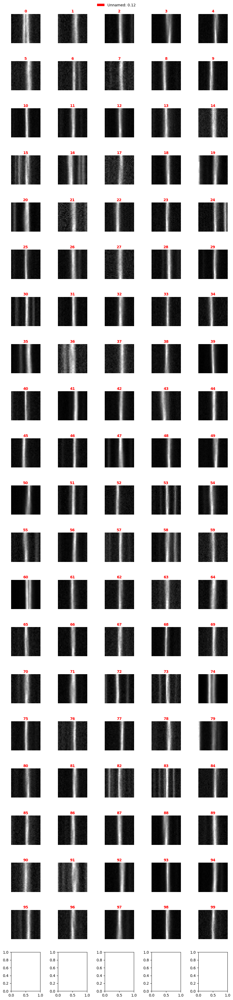

In [53]:
rff.inspect_df_w_stamp_color(final_df, imgsize=15, titlecol=['Unnamed: 0.12'], plot_centers=False)

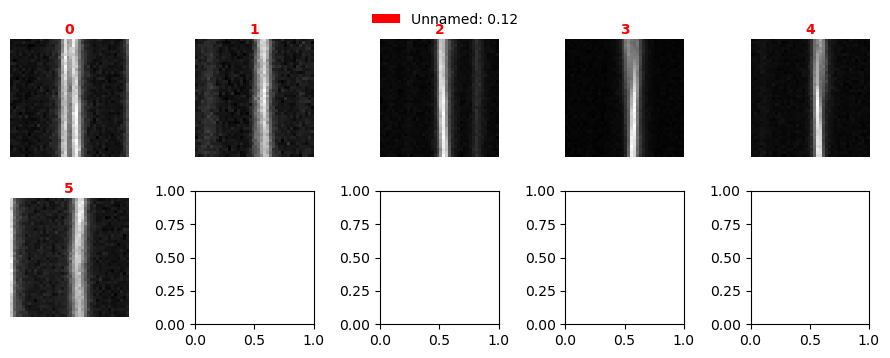

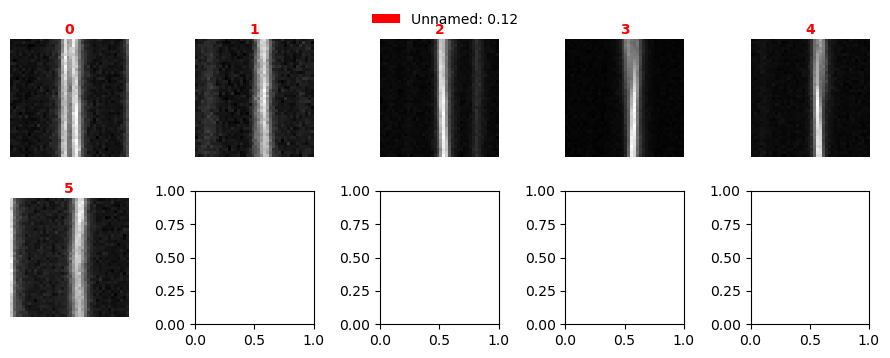

In [9]:
rff.inspect_df_w_stamp_color(final_df[:6], imgsize=20, titlecol=['Unnamed: 0.12'])

In [178]:
final_df_rfgood_filtered['concat_index_copy'][-10:]

125373    127146
272352    276293
239828    243252
149652    151735
4680        4712
3732        3763
274863    278819
115079    116731
272353    276294
258695    262444
Name: concat_index_copy, dtype: int64

In [41]:
final_df.columns

Index(['Unnamed: 0.10', 'Unnamed: 0.9', 'Unnamed: 0.8', 'Unnamed: 0.7',
       'Unnamed: 0.6', 'Unnamed: 0.5', 'Unnamed: 0.4', 'Unnamed: 0.3',
       'Unnamed: 0.2', 'Unnamed: 0.1',
       ...
       'local_average_outside_dimming_denoised', 'height_dimming_denoised',
       'FWHM_dimming_denoised', 'signal_local_dimming_denoised',
       'central_point_dimming_denoised', 'concat_index_copy',
       'snr_local_denoised', 'central_point', 'num_simultaneous_20_p1_space',
       'num_simultaneous_20_p1_time'],
      dtype='object', length=106)

In [179]:
df['concat_index_copy'][-10:]

88    259461
89     24689
90    240845
91     73865
92    130158
93    194123
94    140388
95     34686
96    270751
97    127146
Name: concat_index_copy, dtype: int64

In [38]:
df = pd.read_csv("/home/3155/best_cands")

In [203]:
df['concat_index_copy']

0     340170
1     109774
2      75263
3     250747
4      49200
       ...  
93    194123
94    140388
95     34686
96    270751
97    127146
Name: concat_index_copy, Length: 98, dtype: int64

In [207]:
final_df_rfgood_filtered['concat_index_copy']

335350    340170
108222    109774
143982    145997
74226      75263
247244    250747
           ...  
274863    278819
115079    116731
272353    276294
105226    106710
289236    293353
Name: concat_index_copy, Length: 100, dtype: int64

In [208]:
for i, row in df.iterrows():
    if row['concat_index_copy'] not in final_df_rfgood_filtered['concat_index_copy'].values:
        print(i)

21
27
28
29
30
51
65
73
77


In [223]:
#simultaneous in time: 51969
#bad light curve: 145997
indices_to_ignore = [51969,145997]

In [331]:
final_df_rfgood_filtered3 = make_final_df(nosats[nosats['random_forest_result']==0], filtered='_f3')

KeyError: 'snr_local_f3'

In [227]:
final_df_rfgood_filtered.drop(index=indices_to_ignore)

,Unnamed: 0.9,Unnamed: 0.8,Unnamed: 0.7,Unnamed: 0.6,Unnamed: 0.5,Unnamed: 0.4,Unnamed: 0.3,Unnamed: 0.2,Unnamed: 0.1,Unnamed: 0,...,central_point_dimming_f3,snr_local,snr_global,real_type_local,real_type_global,distance_from_start,random_forest_result,concat_index_copy,snr_local_filtered2,central_point
340170,340170,340170,340170,340170,340170,340170,340170,340170,0,0,...,78.0,2.645553,1.686088,neg,neg,2764.500000,0.0,340170,1.991304,74.0
109774,109774,109774,109774,109774,109774,109774,109774,109774,1,129,...,2153.0,1.549887,1.370316,neg,neg,-696.750000,0.0,109774,1.926008,2153.0
75263,75263,75263,75263,75263,75263,75263,75263,75263,27,113,...,1831.0,1.741268,1.798457,neg,neg,-370.750000,0.0,75263,1.748513,1843.0
250747,250747,250747,250747,250747,250747,250747,250747,250747,0,15,...,766.0,1.771452,1.468635,neg,neg,-24.500000,0.0,250747,1.644846,766.0
49200,49200,49200,49200,49200,49200,49200,49200,49200,116,198,...,2873.0,1.609569,1.321028,pos,pos,-1769.976190,0.0,49200,1.584221,2888.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
194123,194123,194123,194123,194123,194123,194123,194123,194123,73,77,...,2005.0,0.678194,0.626560,pos,pos,744.850000,0.0,194123,1.252562,2017.0
140388,140388,140388,140388,140388,140388,140388,140388,140388,39,14,...,263.0,0.817654,0.605860,pos,pos,1925.166667,0.0,140388,1.252222,272.0
34686,34686,34686,34686,34686,34686,34686,34686,34686,63,33,...,799.0,0.997155,0.894332,pos,pos,2105.500000,0.0,34686,1.252068,812.0
270751,270751,270751,270751,270751,270751,270751,270751,270751,21,18,...,2338.0,0.872667,0.801531,pos,pos,368.062500,0.0,270751,1.250698,2357.0


IndexError: too many indices for array: array is 1-dimensional, but 2 were indexed

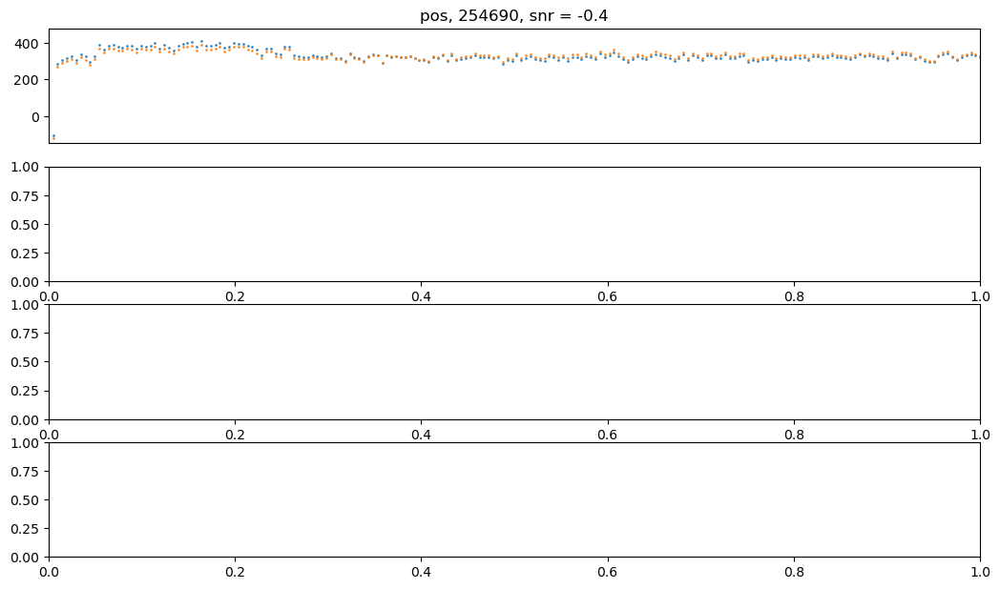

In [348]:
df = final_df_rfgood# [final_df_rfgood['row_from_nn']>50]
concat2=final_df_rfgood 
figrows = 4
fig, ax = plt.subplots(figrows, 1, figsize=(7 * 1.8, figrows * 1.8))

for i, index in enumerate(df.index[:figrows].values):
    # print(index)
    tot, maxols = rff.get_tot_csv(concat2, index)
    ax[i].plot(tot, '.', ms=2, alpha=.8)
    tot_filt = rff.get_tot_csv_filtered_hap2(concat2, index)
    ax[i].plot(tot_filt, '.', ms=2, alpha=.8)
    ax[i].set_title(str(df.loc[index, "real_type_local"])+", "+str(df.loc[index, "concat_index_copy"])+", snr = "+f"{df.loc[index, 'snr_local_filtered2']:.1f}")
    ax[i].set_xticks([])
    ax[i].set_xlim(-1,200)
    # ax[i].plot(tot, '.', ms=5, alpha=.8, c='red')
    if str(df.loc[index, "real_type_local"])=='pos':
        # xes = np.linspace(df.loc[index, 'central_point_brightening_filtere']-15,df.loc[index, 'central_point_brightening_filtere']+14,30)
    #     ax[i,1].set_xlim(df.loc[index, 'central_point_brightening_filtere']-15, df.loc[index, 'central_point_brightening_filtere']+15)
        ax[i,0].plot(tot[int(df.loc[index, 'central_point_brightening_filtere'])-15:int(df.loc[index, 'central_point_brightening_filtere'])+15],  s=15, alpha=.8, c='red', zorder=10)
    elif str(df.loc[index, "real_type_local"])=='neg':
    #     ax[i,1].set_xlim(df.loc[index, 'central_point_dimming_filtere']-15, df.loc[index, 'central_point_dimming_filtere']+15)
        ax[i,0].plot(tot[int(df.loc[index, 'central_point_dimming_filtere'])-15:int(df.loc[index, 'central_point_dimming_filtere'])+15],  s=15, alpha=.8, c='red', zorder=10)


In [349]:
#let's investigate some of these:
# ends = [254690, 174692, 141988, 63398]

In [222]:
len(final_df_rfgood_filtered)

100

In [232]:
final_df_rfgood_filtered.loc[61364, 'filename']

'ztf_20221020148032_000686_zg_c07_x_0029.'

In [231]:
final_df_rfgood_filtered.loc[141275, 'filename']

'ztf_20221020148032_000686_zg_c07_x_0028.'

In [241]:
importlib.reload(rff)

<module 'review_findings_functions' from '/home/3155/rwe/review_findings_functions.py'>

In [263]:
indices_to_plot = [265333,
109774,
75263,
286012, 319001,211457, 83339, 227246, 83339, ]

In [250]:
final_df_rfgood_filtered['concat_index_copy']

340170    340170
109774    109774
145997    145997
75263      75263
250747    250747
           ...  
194123    194123
140388    140388
34686      34686
270751    270751
127146    127146
Name: concat_index_copy, Length: 100, dtype: int64

In [257]:
plotplot = []
for i, row in final_df_rfgood_filtered.iterrows():
    if row['concat_index_copy'] in indices_to_plot:
        plotplot.append(i)

In [56]:
importlib.reload(rff)

<module 'review_findings_functions' from '/home/3155/rwe/review_findings_functions.py'>

In [57]:
%matplotlib inline

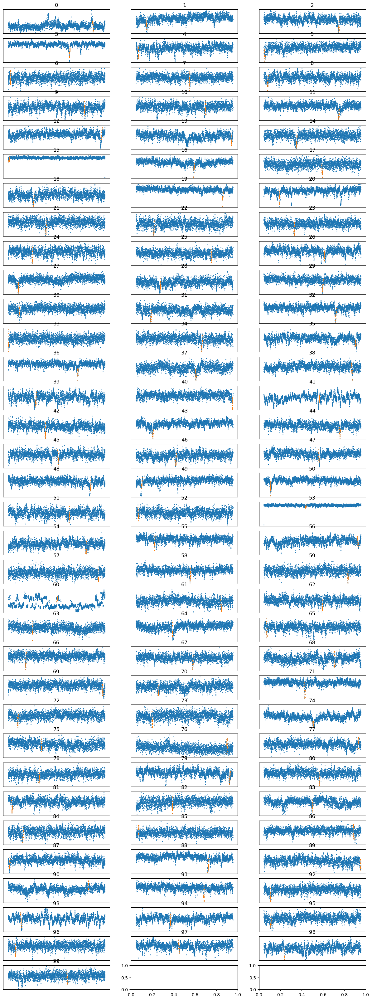

In [58]:
rff.plot_small_multiples_lcs(final_df, final_df)


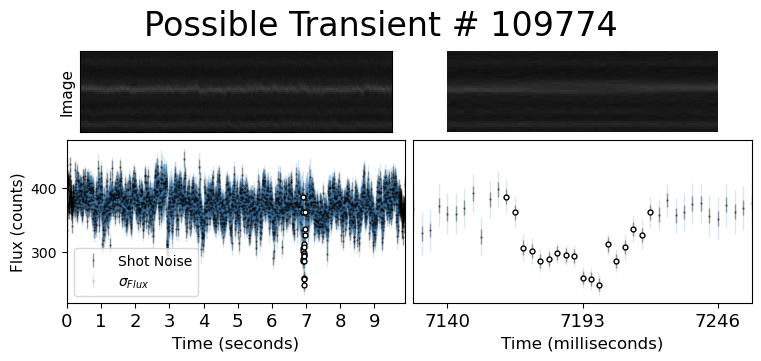

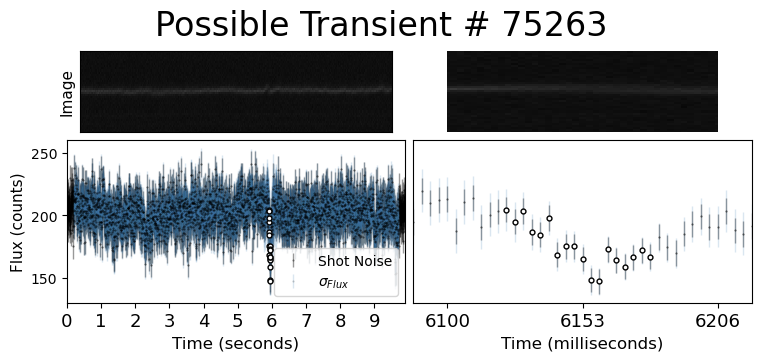

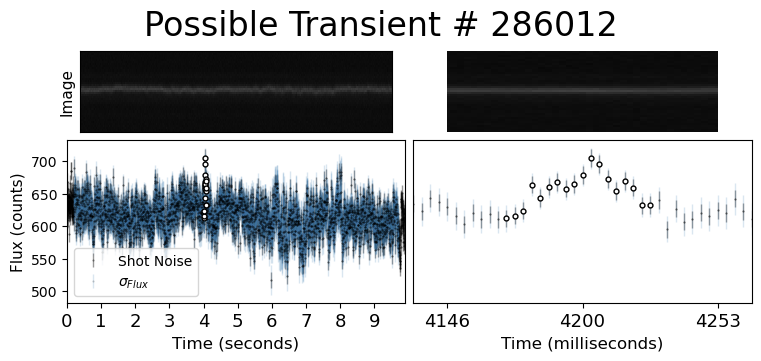

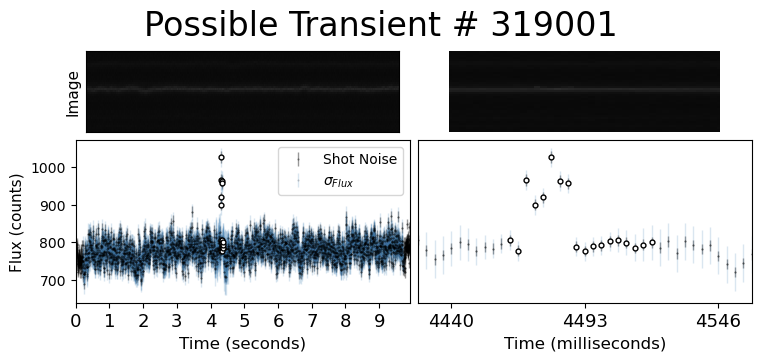

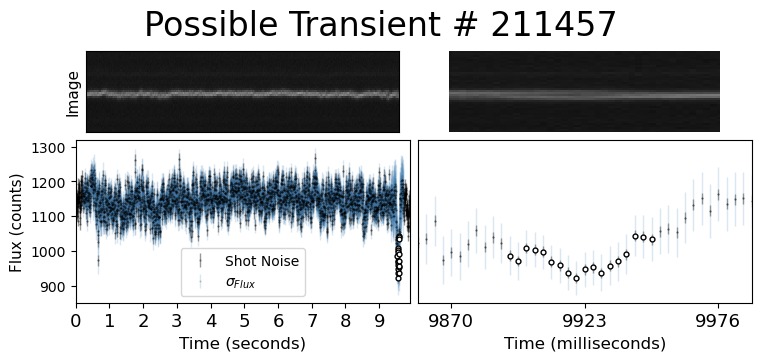

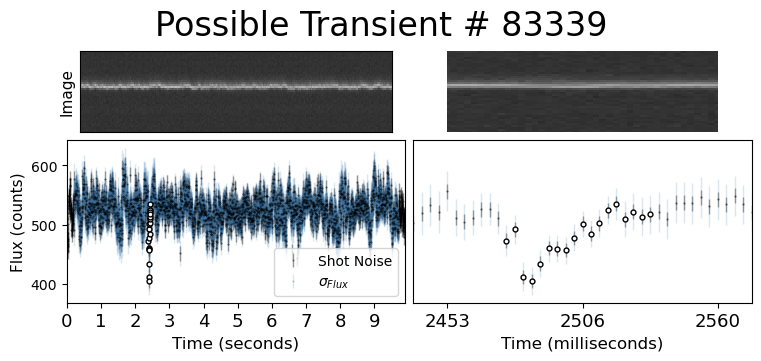

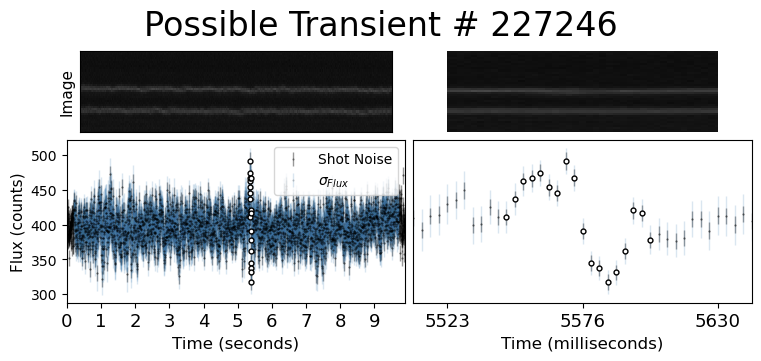

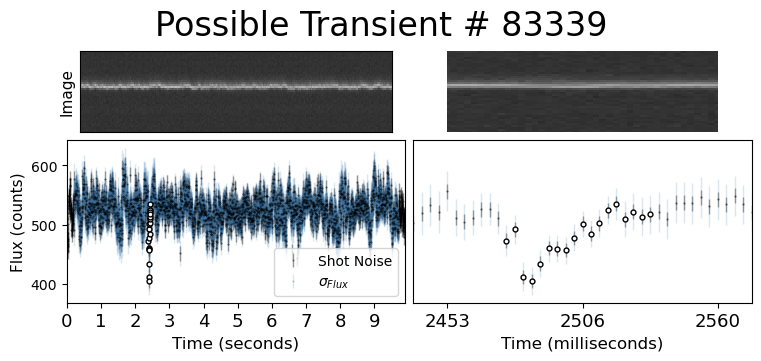

In [278]:
for index in indices_to_plot[1:]:
    rff.plot_time_series_again_aperture(
        final_df_rfgood_filtered,
        index,
        "1020",
        2,
        True
    )
    # break

TypeError: cannot convert the series to <class 'int'>

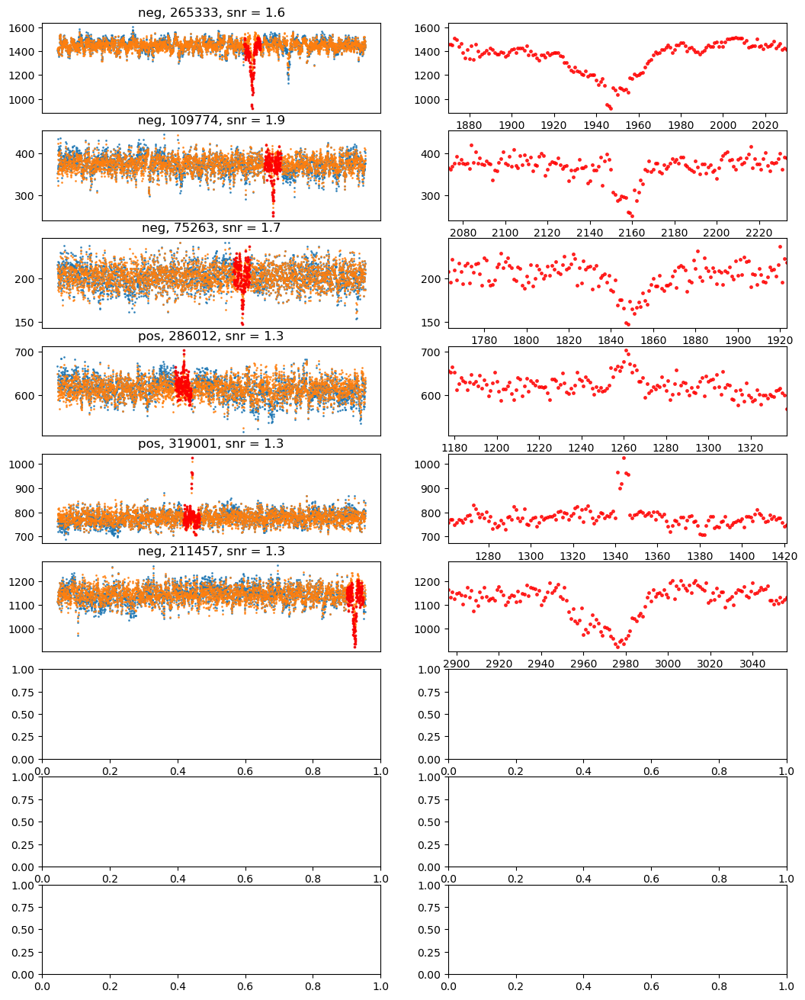

In [ ]:
size = 160
# new = final_df_rfgood_filtered.loc[indices_to_plot]
df = final_df_rfgood_filtered.loc[indices_to_plot]
figrows = len(df)
fig, ax = plt.subplots(figrows, 2, figsize=(7 * 1.8, figrows * 1.8))

for i, index in enumerate(df.index[:figrows].values):
    # print(index)
    tot, maxols = rff.get_tot_csv(df, index)
    ax[i,0].plot(tot, '.', ms=2, alpha=.8)
    tot_filt = rff.get_tot_csv_filtered_hap2(df, index)
    ax[i,0].plot(tot_filt, '.', ms=2, alpha=.8)
    ax[i,0].set_title(str(df.loc[index, "real_type_local"])+", "+str(df.loc[index, "concat_index_copy"])+", snr = "+f"{df.loc[index, 'snr_local_filtered2']:.1f}")
    ax[i,0].set_xticks([])
    ax[i,1].plot(tot, '.', ms=5, alpha=.8, c='red')
    try:
        if str(df.loc[index, "real_type_local"])=='pos':
            range1 = np.max([int(df.loc[index, 'central_point_brightening_filtere']-size//2), 0])
            range2 = np.min([int(df.loc[index, 'central_point_brightening_filtere']+size//2-1), len(tot)])
            xes = np.linspace(range1, range2, range2-range1+1)
            # print(range1, range2, len(tot), len(tot[range1:range2+1]))
            # print(len(xes))
            # print(xes)
            ax[i,1].set_xlim(range1, range2+1)
            ax[i,0].scatter(xes,tot[range1:range2+1],  s=3, alpha=.8, c='red', zorder=10)
        elif str(df.loc[index, "real_type_local"])=='neg':
            
            range1 = np.max([int(df.loc[index, 'central_point_dimming_filtere']-size//2), 0])
            range2 = np.min([int(df.loc[index, 'central_point_dimming_filtere']+size//2-1), len(tot)])
            # print(range1, range2, len(tot), len(tot[range1:range2+1]), len(xes))
            xes = np.linspace(range1, range2, range2-range1+1)
            # print(len(xes))
            # print(xes)
            ax[i,1].set_xlim(range1, range2+1)
            ax[i,0].scatter(xes,tot[range1:range2+1],  s=3, alpha=.8, c='red', zorder=10)
            
            # xes = np.linspace(df.loc[index, 'central_point_dimming_filtere']-size//2,df.loc[index, 'central_point_dimming_filtere']+size//2-1,2*(size//2))
            # # print(len(xes))
            # # print(xes)
            # ax[i,1].set_xlim(df.loc[index, 'central_point_dimming_filtere']-size//2, df.loc[index, 'central_point_dimming_filtere']+size//2)
            # ax[i,0].scatter(xes,tot[int(df.loc[index, 'central_point_dimming_filtere'])-size//2:int(df.loc[index, 'central_point_dimming_filtere'])+size//2],  s=15, alpha=.8, c='red', zorder=10)
    except TypeError:
        pass

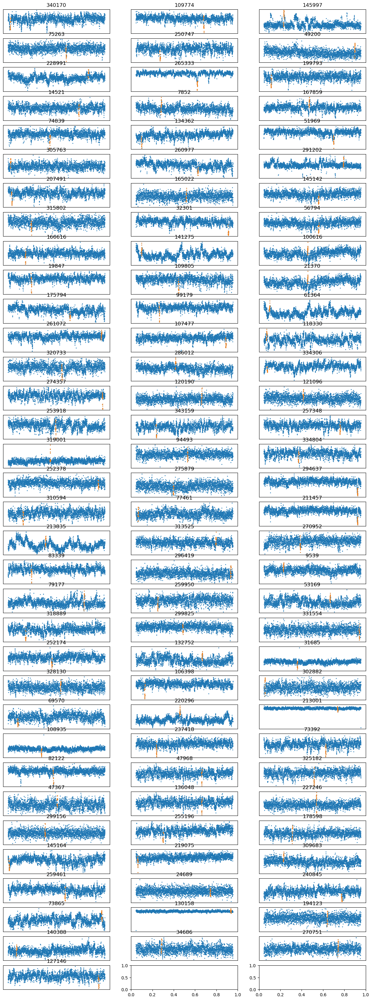

In [262]:
# print("With random forest, unfiltered snrs")
rff.plot_small_multiples_lcs(final_df_rfgood_filtered, nosats, 'concat_index_copy')


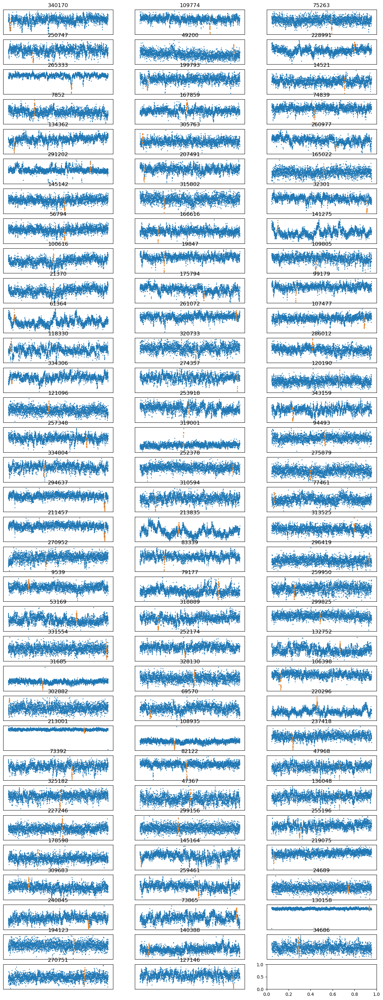

In [243]:
# print("With random forest, unfiltered snrs")
rff.plot_small_multiples_lcs(final_df_rfgood_filtered.drop(index=indices_to_ignore), nosats, 'concat_index_copy')


In [49]:
index = 254690
df = final_df_rfgood
if type(df.loc[index, "original_rows_from_nn"])==str:
    aggrows = np.fromstring(df.loc[index, "original_rows_from_nn"][1:-1], dtype=float, sep=',')
else:
    aggrows = df.loc[index, "original_rows_from_nn"] + wid
    #first brightening
snr_local, snr_global, noise_local, noise_global, local_average_outside, height, FWHM, signal_local, tallest_index_absolute = rff.get_snr_brightest(tot, aggrows) 

lower, newwid, upper:  10 10 10
tallest_index 13
tallest_index_absolute 3


In [363]:
final_df_rfgood.loc[141988, ['original_rows_from_nn', 'original_types',  'snr_local_dimming', 
       'noise_local_dimming', 
       'local_average_outside_dimming', 'height_dimming', 'FWHM_dimming',
       'signal_local_dimming', 'central_point_dimming', 
         'snr_local_dimming_filtered2',
       'snr_global_dimming_filtered2', 'noise_local_dimming_filtered2',
       'noise_global_dimming_filtered', 'height_dimming_filtered2',
       'FWHM_dimming_filtered2', 'signal_local_dimming_filtered',
       'central_point_dimming_filtere','real_type_local']]

original_rows_from_nn            [30.61111111]
original_types                         ['pos']
snr_local_dimming                      1.87817
noise_local_dimming                   17.91209
local_average_outside_dimming       708.237677
height_dimming                      -98.395269
FWHM_dimming                              14.0
signal_local_dimming                 33.641944
central_point_dimming                     32.0
snr_local_dimming_filtered2           0.694933
snr_global_dimming_filtered2          0.736521
noise_local_dimming_filtered2        17.557757
noise_global_dimming_filtered        16.566331
height_dimming_filtered2            -80.762225
FWHM_dimming_filtered2                     2.0
signal_local_dimming_filtered        12.201457
central_point_dimming_filtere             28.0
real_type_local                            neg
Name: 141988, dtype: object

In [359]:
final_df_rfgood.loc[254690, ['original_rows_from_nn', 'original_types', 'snr_local_brightening',
       'noise_local_brightening',
       'local_average_outside_brightening',
       'height_brightening', 'FWHM_brightening', 'signal_local_brightening',
       'central_point_brightening', 
        'snr_local_brightening_filtered2',
        'noise_local_brightening_filtered2',
        'height_brightening_filtered2',
       'FWHM_brightening_filtered2', 'signal_local_brightening_filtered',
       'central_point_brightening_filtere', 
        'real_type_local']]

original_rows_from_nn                      [0.]
original_types                          ['pos']
snr_local_brightening                  3.757073
noise_local_brightening               12.577022
local_average_outside_brightening    574.730842
height_brightening                    67.323155
FWHM_brightening                           35.0
signal_local_brightening              47.252795
central_point_brightening                  13.0
snr_local_brightening_filtered2       -0.405905
noise_local_brightening_filtered2     12.303808
height_brightening_filtered2          -27.07398
FWHM_brightening_filtered2                  4.0
signal_local_brightening_filtered     -4.994181
central_point_brightening_filtere          -4.0
real_type_local                             pos
Name: 254690, dtype: object

In [360]:
final_df_rfgood.loc[174692, ['original_rows_from_nn', 'original_types', 'snr_local_brightening',
       'noise_local_brightening',
       'local_average_outside_brightening',
       'height_brightening', 'FWHM_brightening', 'signal_local_brightening',
       'central_point_brightening', 
        'snr_local_brightening_filtered2',
        'noise_local_brightening_filtered2',
        'height_brightening_filtered2',
       'FWHM_brightening_filtered2', 'signal_local_brightening_filtered',
       'central_point_brightening_filtere', 
        'real_type_local']]

original_rows_from_nn                      [0.]
original_types                          ['pos']
snr_local_brightening                  2.006948
noise_local_brightening               18.081318
local_average_outside_brightening    568.460028
height_brightening                    79.980884
FWHM_brightening                           23.0
signal_local_brightening              36.288259
central_point_brightening                  14.0
snr_local_brightening_filtered2       -0.326924
noise_local_brightening_filtered2     15.813637
height_brightening_filtered2         -22.508015
FWHM_brightening_filtered2                  2.0
signal_local_brightening_filtered     -5.169862
central_point_brightening_filtere          -2.0
real_type_local                             pos
Name: 174692, dtype: object

In [364]:
final_df_rfgood.loc[63398, ['original_rows_from_nn', 'original_types',  'snr_local_dimming', 
       'noise_local_dimming', 
       'local_average_outside_dimming', 'height_dimming', 'FWHM_dimming',
       'signal_local_dimming', 'central_point_dimming', 
         'snr_local_dimming_filtered2',
       'snr_global_dimming_filtered2', 'noise_local_dimming_filtered2',
       'noise_global_dimming_filtered', 'height_dimming_filtered2',
       'FWHM_dimming_filtered2', 'signal_local_dimming_filtered',
       'central_point_dimming_filtere','real_type_local']]

original_rows_from_nn            [30.61111111]
original_types                         ['pos']
snr_local_dimming                     1.873248
noise_local_dimming                   18.04662
local_average_outside_dimming       708.313226
height_dimming                      -98.153673
FWHM_dimming                              14.0
signal_local_dimming                   33.8058
central_point_dimming                     32.0
snr_local_dimming_filtered2           0.701192
snr_global_dimming_filtered2          0.743296
noise_local_dimming_filtered2        17.565382
noise_global_dimming_filtered        16.570376
height_dimming_filtered2            -80.884656
FWHM_dimming_filtered2                     2.0
signal_local_dimming_filtered        12.316698
central_point_dimming_filtere             28.0
real_type_local                            neg
Name: 63398, dtype: object

With random forest, unfiltered snrs


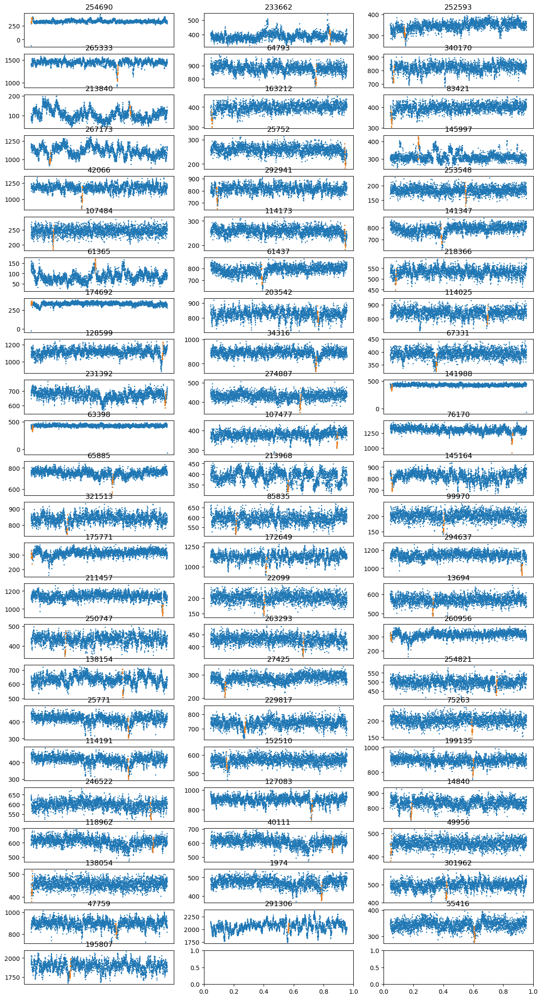

In [332]:
print("With random forest, unfiltered snrs")
rff.plot_small_multiples_lcs(final_df_rfgood[:70], nosats, 'concat_index_copy')


With random forest, filtered snrs


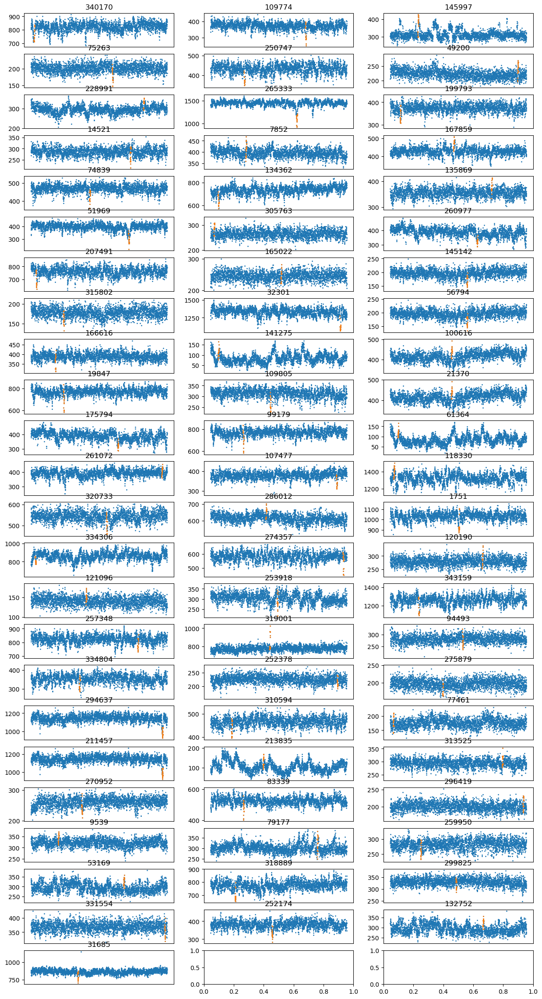

In [329]:
print("With random forest, filtered snrs")
rff.plot_small_multiples_lcs(final_df_rfgood_filtered[:70], nosats, 'concat_index_copy')


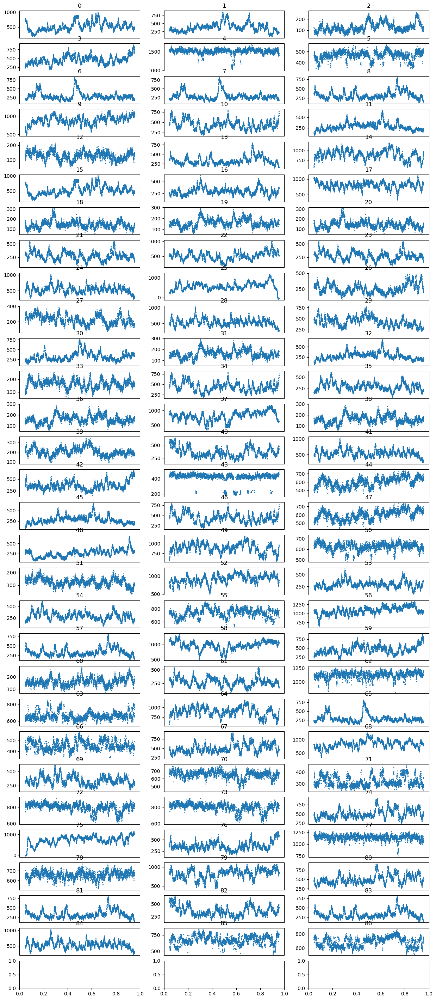

In [128]:
rff.plot_small_multiples_lcs(final_df[final_df['random_forest_result']==1], concat)

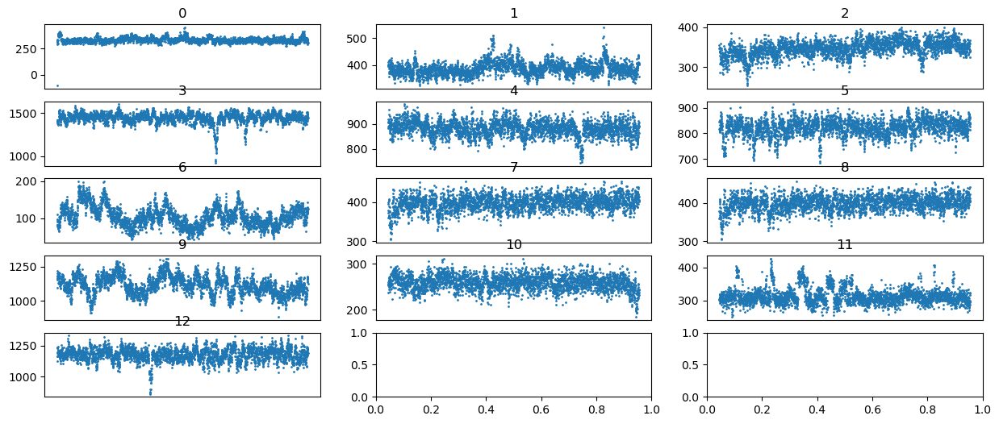

In [129]:
rff.plot_small_multiples_lcs(final_df[final_df['random_forest_result']==0], concat)

/home/3155/rwe/review_findings_functions.py:2257: UserWarning: Attempting to set identical low and high ylims makes transformation singular; automatically expanding.
  ax[i, j].imshow(stamp, vmax=clim)


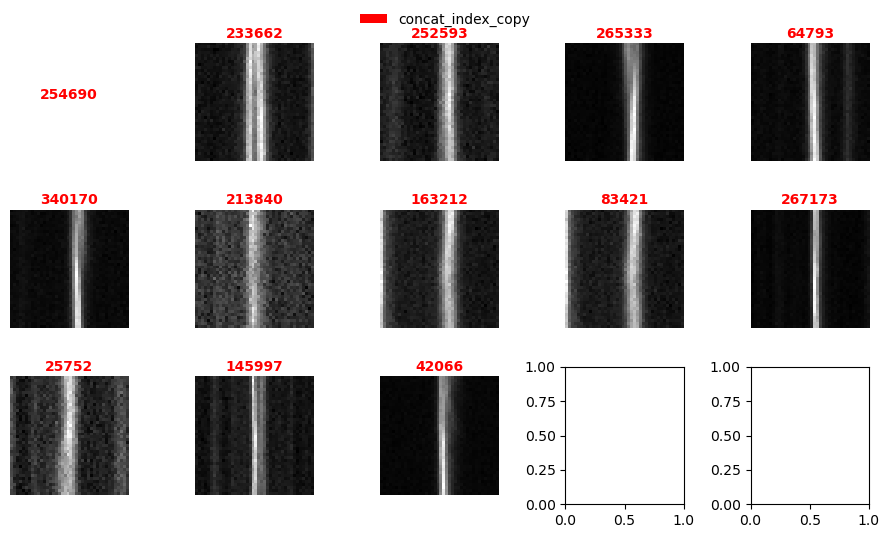

In [127]:
rff.inspect_df_w_stamp_color(final_df[final_df['random_forest_result']==0], titlecol=['concat_index_copy'], imgsize=20)

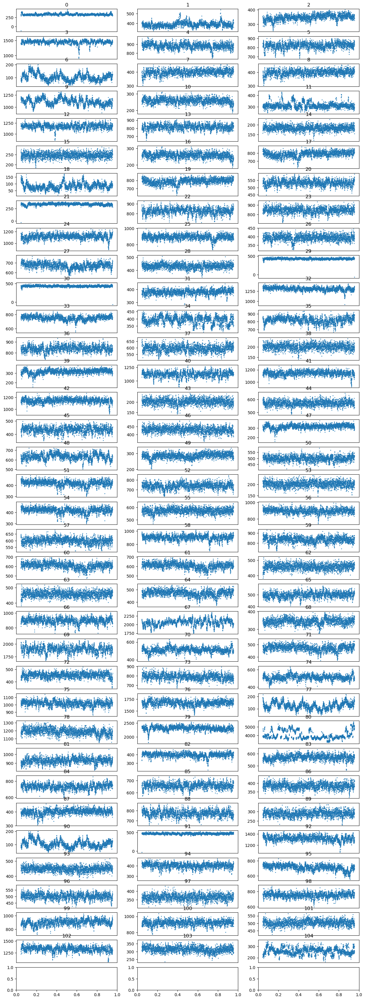

In [140]:
rff.plot_small_multiples_lcs(final_df_big[final_df_big['random_forest_result']==0], final_df_big)

In [ ]:
#moresats
[133395, 53727, 326040, 244374, 247862, 139635, 44003, 184032, 97098

In [211]:
final_df_rfgood_filtered

,Unnamed: 0.10,Unnamed: 0.9,Unnamed: 0.8,Unnamed: 0.7,Unnamed: 0.6,Unnamed: 0.5,Unnamed: 0.4,Unnamed: 0.3,Unnamed: 0.2,Unnamed: 0.1,...,snr_local,snr_global,real_type_local,real_type_global,distance_from_start,random_forest_result,brightness_ranking,concat_index_copy,snr_local_filtered2,central_point
335350,340170,340170,340170,340170,340170,340170,340170,340170,340170,0,...,2.645553,1.686088,neg,neg,2764.500000,0.0,0.0,340170,1.991304,74.0
108222,109774,109774,109774,109774,109774,109774,109774,109774,109774,1,...,1.549887,1.370316,neg,neg,-696.750000,0.0,14.0,109774,1.926008,2153.0
143982,145997,145997,145997,145997,145997,145997,145997,145997,145997,4,...,2.129372,1.394781,pos,pos,-149.428571,0.0,18.0,145997,1.911613,632.0
74226,75263,75263,75263,75263,75263,75263,75263,75263,75263,27,...,1.741268,1.798457,neg,neg,-370.750000,0.0,5.0,75263,1.748513,1843.0
247244,250747,250747,250747,250747,250747,250747,250747,250747,250747,0,...,1.771452,1.468635,neg,neg,-24.500000,0.0,3.0,250747,1.644846,766.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
274863,278819,278819,278819,278819,278819,278819,278819,278819,278819,40,...,1.126440,0.967729,pos,pos,1026.000000,0.0,9.0,278819,1.242029,431.0
115079,116731,116731,116731,116731,116731,116731,116731,116731,116731,39,...,1.061865,0.880168,neg,neg,1328.000000,0.0,11.0,116731,1.241657,52.0
272353,276294,276294,276294,276294,276294,276294,276294,276294,276294,8,...,1.332030,1.078894,pos,pos,1474.835784,0.0,6.0,276294,1.241553,993.0
105226,106710,106710,106710,106710,106710,106710,106710,106710,106710,2,...,1.258812,1.235634,pos,pos,-98.333333,0.0,11.0,106710,1.237331,359.0


In [216]:
final_df_rfgood_filtered.to_csv('/home/3155/best_cands_no_0029')

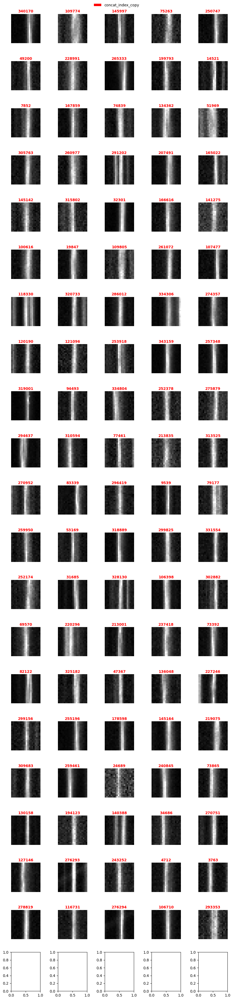

In [199]:
rff.inspect_df_w_stamp_color(final_df_rfgood_filtered, titlecol=['concat_index_copy'], imgsize=10)

In [27]:
#last is simultaneity
#get_simultaneous_ones(index, our_cands, df_last,  snr_limit=.1, threshold=20)
#- [ ] Look if there is a candidate that is simultaneous algorithmically
# - [ ] And if yes then plot with the brightest light curves in the image, ordered by x position
# - [ ] Make sure the scale doesn’t get too compressed
# concat_filtered
our_cands = final_df
df_last = nosats
# rff.get_simultaneous_ones(our_cands.index[0], our_cands, df_last,  snr_limit=.1, threshold=20)

In [28]:
num_simultaneous_20_p1_time = []
num_simultaneous_20_p1_space = []
for i, row in our_cands.iterrows():
    indices = rff.get_simultaneous_image_ones(i, our_cands, df_last,  snr_limit=.1, threshold=20)
    indices2 = rff.get_simultaneous_ones(i, our_cands, df_last,  snr_limit=.1, threshold=20)
    num_simultaneous_20_p1_space.append(indices)
    num_simultaneous_20_p1_time.append(indices2)
our_cands['num_simultaneous_20_p1_space']=num_simultaneous_20_p1_space
our_cands['num_simultaneous_20_p1_time']=num_simultaneous_20_p1_time

In [63]:
importlib.reload(rff)

<module 'review_findings_functions' from '/home/3155/rwe/review_findings_functions.py'>

In [64]:
# num_simultaneous_10_p1_time = []
# num_simultaneous_10_p1_space = []
# for i, row in our_cands.iterrows():
#     indices = rff.get_simultaneous_image_ones(i, our_cands, df_last,  snr_limit=.1, threshold=10)
#     indices2 = rff.get_simultaneous_ones(i, our_cands, df_last,  snr_limit=.1, threshold=10)
#     num_simultaneous_10_p1_space.append(indices)
#     num_simultaneous_10_p1_time.append(indices2)
# our_cands['num_simultaneous_10_p1_space']=num_simultaneous_10_p1_space
# our_cands['num_simultaneous_10_p1_time']=num_simultaneous_10_p1_time

/tmp/ipykernel_45398/1374439462.py:8: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  our_cands['num_simultaneous_10_p1_space']=num_simultaneous_10_p1_space
/tmp/ipykernel_45398/1374439462.py:9: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  our_cands['num_simultaneous_10_p1_time']=num_simultaneous_10_p1_time


In [57]:
for i, row in our_cands.iterrows():
    
    indices = row['num_simultaneous_20_p1_time'] #space
    print(indices)
    if len(indices)==2:
        # plot_lcs_together_images(i, indices[1],  df=concat)
        plot_lcs_together(indices[0], indices[1], df=df_last, zoom=200)
        plt.show()
    if len(indices)>2:
        # plot_lcs_together_images(i, indices[1],  df=concat)
        plot_lcs_together(indices[0], indices[1], indices[2],df=df_last, zoom=200)
        plt.show()

[340170]
[109774]
[145997]
[75263]
[250747, 250764]


NameError: name 'plot_lcs_together' is not defined

[254690]
[233662]
[252593]
[265333]
[64793, 64785, 64810]


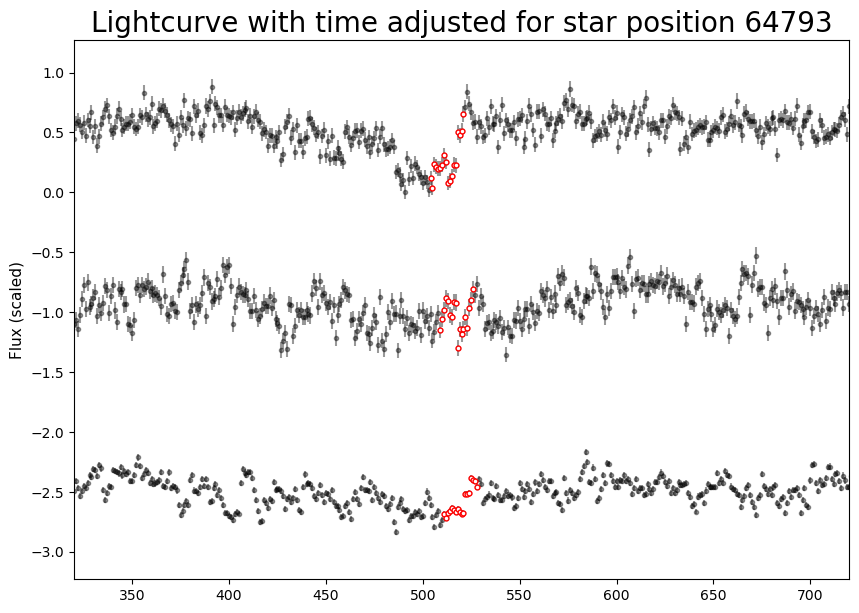

[340170]
[213840]
[163212]
[83421]
[267173]
[25752, 25760, 25817]


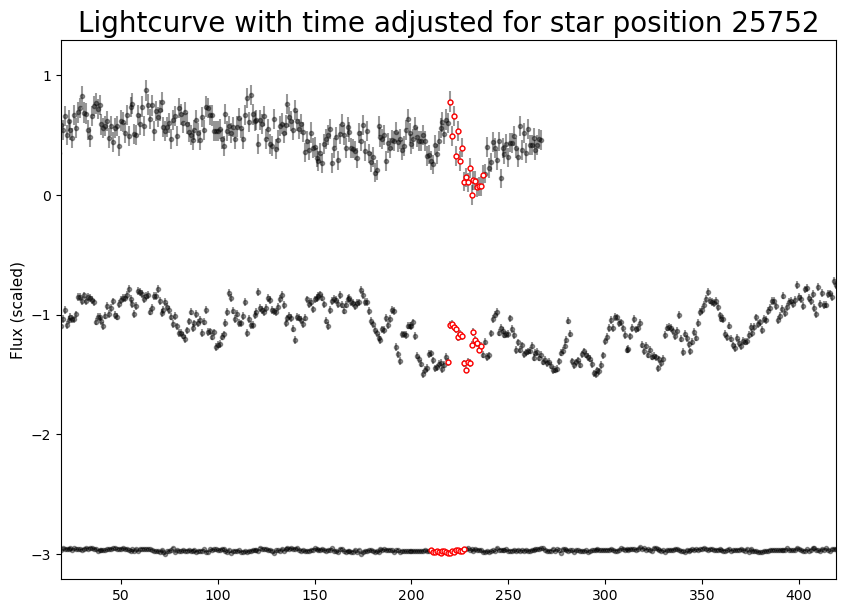

[145997]
[42066]


In [72]:
for i, row in our_cands.iterrows():
    
    indices = row['num_simultaneous_10_p1_time'] #space
    print(indices)
    if len(indices)==2:
        # plot_lcs_together_images(i, indices[1],  df=concat)
        plot_lcs_together(indices[0], indices[1], df=df_last, zoom=200)
        plt.show()
    if len(indices)>2:
        # plot_lcs_together_images(i, indices[1],  df=concat)
        plot_lcs_together(indices[0], indices[1], indices[2],df=df_last, zoom=200)
        plt.show()

In [87]:
lc_list, to_subtract = make_brightest_lcs_array(25752, our_cands)

In [90]:
np.shape(lc_list)

(10, 3080)

In [124]:
importlib.reload(rff)

<module 'review_findings_functions' from '/home/3155/rwe/review_findings_functions.py'>

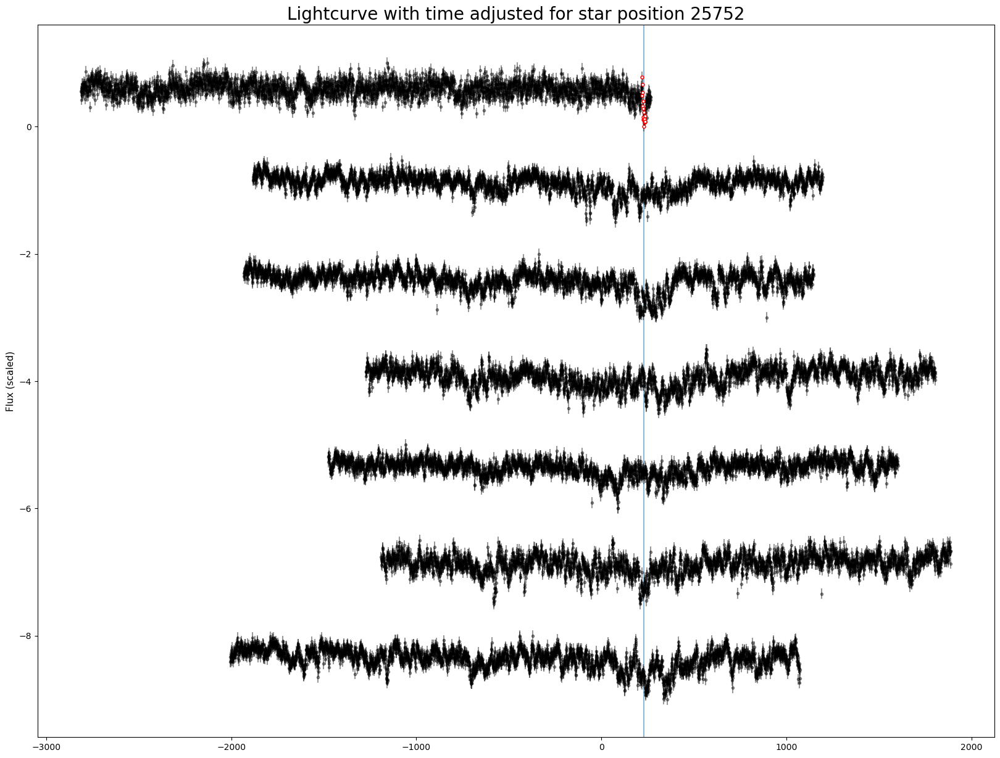

In [125]:
rff.plot_lcs_from_file(25752, our_cands)

In [29]:
def plot_lcs_simultaneous_with_spatial(rindex, indices, df, time_adjusted=True, hap=2,
                                        xmin=None, xmax=None, zoom=None,
                                        use_snr_center=True, number=6):
    '''
    Plots the primary transient candidate light curve, all simultaneously-flagged
    event LCs (highlighted with blue-ring markers), and the `number` spatially
    nearest stars on each side (by x-position, pulled from the xy_arrays FITS
    file since most aren't transient candidates in df). Skips neighbors whose
    curve doesn't overlap the primary's highlighted time window, continuing to
    further neighbors until `number` valid ones are found per side.
    Stars with x < primary are plotted ABOVE, x >= primary plotted BELOW.
    Each curve is annotated at the left edge with its x-distance from the
    primary candidate's closest_x (signed, with left/right direction).
    hap: half aperture for light curve, allowable from 2 to 5
    number: how many spatial neighbors to plot on EACH side
    '''
    fig, ax = plt.subplots(figsize=(20, 15))
    lightcurve_path = '/lustre/lrspec/ZTF_data/lightcurves/1020/'

    def get_row_num(df_row):
        row_num = int(df_row['row_from_nn']) + 10
        if use_snr_center:
            if df_row['real_type_local'] == 'pos':
                row_num = int(df_row['central_point_brightening'])
            elif df_row['real_type_local'] == 'neg':
                row_num = int(df_row['central_point_dimming'])
        return row_num

    def load_lc(df_row):
        lc_filename = (
            'lightcurve_' + df_row['filename'][:-1] + '_' +
            str(df_row['quadrant']) + '_' +
            f'{int(df_row["closest_x"]):04}' + '_' +
            f'{int(df_row["closest_y"]):04}' + '.csv'
        )
        return pd.read_csv(lightcurve_path + lc_filename)

    def make_distance_label(x_val):
        diff = x_val - primary_x
        direction = "right" if diff >= 0 else "left"
        return f"{diff:+.0f} px {direction}"

    def annotate_distance(label, offset, ax):
        ax.annotate(
            label,
            xy=(0, -offset),
            xycoords=("axes fraction", "data"),
            xytext=(5, 0),
            textcoords="offset points",
            ha="left", va="center",
            fontsize=9, color="dimgray",
            annotation_clip=False
        )

    def plot_lc_from_row(df_row, offset, ax, highlight=False, is_primary=False,
                      label=None):
        lc_df = load_lc(df_row)
        timeseries = lc_df['flux_hap_' + str(hap)][2:]
        ts_min, ts_max = np.min(timeseries), np.max(timeseries)
        tot = (timeseries - ts_min) / (ts_max - ts_min) - offset
        
        fluxerr = np.sqrt(timeseries / 6.2 + 8.5**2) / (ts_max - ts_min)
        remove = int(df_row["closest_y"]) if time_adjusted else 0
        row_num = get_row_num(df_row)
        x = np.arange(len(tot))
        _plot_curve(x, tot, fluxerr, remove, row_num, ax, highlight, is_primary)
        if label is not None:
            annotate_distance(label, offset, ax)
        return remove, row_num

    def plot_lc_from_array(timeseries, y_pos, offset, ax, label=None):
        timeseries = np.asarray(timeseries)[2:]
        ts_min, ts_max = np.min(timeseries), np.max(timeseries)
        tot = (timeseries - ts_min) / (ts_max - ts_min) - offset
        
        fluxerr = np.sqrt(timeseries / 6.2 + 8.5**2) / (ts_max - ts_min)
        remove = int(y_pos) if time_adjusted else 0
        x = np.arange(len(tot))
        _plot_curve(x, tot, fluxerr, remove, None, ax, highlight=False, is_primary=False)
        if label is not None:
            annotate_distance(label, offset, ax)

    def _plot_curve(x, tot, fluxerr, remove, row_num, ax, highlight, is_primary):
        ax.errorbar(
            x - remove, tot, yerr=fluxerr,
            color="black", ecolor="black",
            linestyle="none", marker=".", alpha=0.4
        )
        if highlight and row_num is not None:
            ax.plot(
                x[row_num - 9: row_num + 9] - remove,
                tot[row_num - 9: row_num + 9],
                color="white", linestyle="none", marker=".",
                markersize=7, markeredgecolor="blue", zorder=10
            )
        if is_primary and row_num is not None:
            ax.axvline(row_num - remove, alpha=0.5)
            ax.plot(
                x[row_num - 9: row_num + 9] - remove,
                tot[row_num - 9: row_num + 9],
                color="white", linestyle="none", marker=".",
                markersize=7, markeredgecolor="red", zorder=10
            )

    # --- Primary LC ---
    primary_row = df.loc[rindex]
    primary_x = primary_row['closest_x']
    primary_remove, primary_row_num = plot_lc_from_row(
        primary_row, offset=0, ax=ax, is_primary=True
    )

    # --- Simultaneous event LCs (split by side) ---
    simul_indices = [s for s in indices if s != rindex]
    simul_above = sorted(
        [s for s in simul_indices if df.loc[s, 'closest_x'] < primary_x],
        key=lambda s: primary_x - df.loc[s, 'closest_x']
    )
    simul_below = sorted(
        [s for s in simul_indices if df.loc[s, 'closest_x'] >= primary_x],
        key=lambda s: df.loc[s, 'closest_x'] - primary_x
    )

    for rank, sidx in enumerate(simul_above):
        x_val = df.loc[sidx, 'closest_x']
        plot_lc_from_row(df.loc[sidx], offset=-(rank + 1) * 1.5, ax=ax,
                          highlight=True, label=make_distance_label(x_val))
    for rank, sidx in enumerate(simul_below):
        x_val = df.loc[sidx, 'closest_x']
        plot_lc_from_row(df.loc[sidx], offset=(rank + 1) * 1.5, ax=ax,
                          highlight=True, label=make_distance_label(x_val))

    n_simul_above = len(simul_above)
    n_simul_below = len(simul_below)

    # --- Spatial neighbor LCs from FITS array ---
    exclude_positions = {
        (int(df.loc[s, 'closest_x']), int(df.loc[s, 'closest_y'])) for s in simul_indices
    }
    target_window = (
        primary_row_num - 9 - primary_remove,
        primary_row_num + 9 - primary_remove
    )
    left_lcs, right_lcs = make_nearest_lcs_array(
        rindex, df, primary_x, target_window, number=number,
        exclude_positions=exclude_positions, time_adjusted=time_adjusted
    )
    # Need x-positions of the chosen neighbors for labels; recompute alongside
    # by re-deriving from y/x pairing already filtered in make_nearest_lcs_array.
    # Simplest: have make_nearest_lcs_array also return x positions.

    for j, (lc, y_pos, x_pos) in enumerate(left_lcs):
        offset = -(n_simul_above + j + 1) * 1.5
        plot_lc_from_array(lc, y_pos, offset, ax, label=make_distance_label(x_pos))

    for j, (lc, y_pos, x_pos) in enumerate(right_lcs):
        offset = (n_simul_below + j + 1) * 1.5
        plot_lc_from_array(lc, y_pos, offset, ax, label=make_distance_label(x_pos))

    # --- Labels / limits ---
    title_tag = "with" if time_adjusted else "with NOT"
    ax.set_title(
        f"Lightcurve {title_tag} time adjusted for star position {rindex}",
        fontsize=20
    )
    ax.set_ylabel("Flux (scaled)", fontsize=11)
    ax.set_xlim(xmin, xmax)
    if zoom is not None:
        ax.set_xlim(
            primary_row_num - zoom - primary_remove,
            primary_row_num + zoom - primary_remove
        )
    fig.show()

In [116]:
our_cands.columns

Index(['Unnamed: 0.8', 'Unnamed: 0.7', 'Unnamed: 0.6', 'Unnamed: 0.5',
       'Unnamed: 0.4', 'Unnamed: 0.3', 'Unnamed: 0.2', 'Unnamed: 0.1',
       'Unnamed: 0', 'filename', 'quad', 'type', 'row_from_nn', 'col_from_nn',
       'detection_size', 'closest_x', 'closest_y', 'Diff',
       'original_cols_from_nn', 'original_rows_from_nn', 'detection_sizes',
       'modified_flag', 'original_types', 'snr_local_brightening',
       'snr_global_brightening', 'noise_local_brightening',
       'noise_global_brightening', 'local_average_outside_brightening',
       'height_brightening', 'FWHM_brightening', 'signal_local_brightening',
       'central_point_brightening', 'snr_local_dimming', 'snr_global_dimming',
       'noise_local_dimming', 'noise_global_dimming',
       'local_average_outside_dimming', 'height_dimming', 'FWHM_dimming',
       'signal_local_dimming', 'central_point_dimming', 'quadrant',
       'num_in_file_in_star', 'Band', 'snr_local_brightening_filtered2',
       'snr_global_b

In [125]:
our_cands

,Unnamed: 0.8,Unnamed: 0.7,Unnamed: 0.6,Unnamed: 0.5,Unnamed: 0.4,Unnamed: 0.3,Unnamed: 0.2,Unnamed: 0.1,Unnamed: 0,filename,...,snr_global,real_type_local,real_type_global,distance_from_start,random_forest_result,concat_index_copy,snr_local_filtered2,central_point,num_simultaneous_20_p1_space,num_simultaneous_20_p1_time
340170,340170,340170,340170,340170,340170,340170,340170,0,0,ztf_20221020294271_000449_zr_c14_x_0016.,...,1.686088,neg,neg,2764.500000,0.0,340170,1.991304,74.0,[340170],[340170]
109774,109774,109774,109774,109774,109774,109774,109774,1,129,ztf_20221020148032_000686_zg_c03_x_0020.,...,1.370316,neg,neg,-696.750000,0.0,109774,1.926008,2153.0,[109774],[109774]
145997,145997,145997,145997,145997,145997,145997,145997,4,0,ztf_20221020141806_000686_zi_c01_x_0025.,...,1.394781,pos,pos,-149.428571,0.0,145997,1.911613,632.0,"[145997, 145994]",[145997]
75263,75263,75263,75263,75263,75263,75263,75263,27,113,ztf_20221020297847_000449_zr_c16_x_0017.,...,1.798457,neg,neg,-370.750000,0.0,75263,1.748513,1843.0,"[75263, 75274]",[75263]
250747,250747,250747,250747,250747,250747,250747,250747,0,15,ztf_20221020297847_000449_zr_c14_x_0015.,...,1.468635,neg,neg,-24.500000,0.0,250747,1.644846,766.0,[250747],"[250747, 250764]"
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
73865,73865,73865,73865,73865,73865,73865,73865,6,40,ztf_20221020148032_000686_zg_c05_x_0025.,...,0.958238,pos,pos,-178.750000,0.0,73865,1.253039,2977.0,"[73865, 73888]",[73865]
130158,130158,130158,130158,130158,130158,130158,130158,6,43,ztf_20221020154120_000640_zi_c01_x_0003.,...,0.627992,pos,pos,-2554.312500,0.0,130158,1.252824,3013.0,"[130158, 130163]",[130158]
194123,194123,194123,194123,194123,194123,194123,194123,73,77,ztf_20221020294271_000449_zr_c16_x_0020.,...,0.626560,pos,pos,744.850000,0.0,194123,1.252562,2017.0,[194123],"[194123, 194093]"
140388,140388,140388,140388,140388,140388,140388,140388,39,14,ztf_20221020148032_000686_zg_c01_x_0022.,...,0.605860,pos,pos,1925.166667,0.0,140388,1.252222,272.0,"[140388, 140419]",[140388]


In [31]:
cands_sim = our_cands[len(our_cands['num_simultaneous_20_p1_time'].values)>1]

KeyError: True

In [30]:
nosats.index.is_unique

True

In [32]:
def make_nearest_lcs_array(rindex, df, primary_x, target_window, number=6,
                            exclude_positions=None, time_adjusted=True):
    '''
    Same as before, but returns (lc, y, x) tuples per neighbor so callers
    can label each curve with its distance from the primary.
    '''
    hap = 2
    lightcurve_path = '/lustre/lrspec/ZTF_data/lightcurves/1020/'
    df_row = df.loc[rindex]
    image_filename = df_row['filename']
    quad = df_row['quadrant']

    xy_file = ("/lustre/lrspec/ZTF_data/corrected_coordinates/xy_arrays/" +
               image_filename[:-6] + "_" + str(quad) + ".fits")

    try:
        with fits.open(xy_file) as hdul_xy:
            data = hdul_xy[1].data
            stored_x = data["X"]
            stored_y = data["Y"]
    except Exception:
        print("ISSUES")
        return [], []

    if exclude_positions is None:
        exclude_positions = set()
    exclude_positions = set(exclude_positions) | {
        (int(df_row["closest_x"]), int(df_row["closest_y"]))
    }

    candidates = []
    for index in range(len(stored_x)):
        x_val, y_val = int(stored_x[index]), int(stored_y[index])
        if (x_val, y_val) in exclude_positions:
            continue
        candidates.append((x_val, y_val, abs(x_val - primary_x)))

    left_candidates = sorted(
        [c for c in candidates if c[0] < primary_x], key=lambda c: c[2]
    )
    right_candidates = sorted(
        [c for c in candidates if c[0] >= primary_x], key=lambda c: c[2]
    )

    def curve_overlaps_window(n_points, remove):
        lo, hi = -remove, n_points - 1 - remove
        target_lo, target_hi = target_window
        return hi >= target_lo and lo <= target_hi

    def load_curves_until_n(cand_list, n_needed):
        results = []
        for x_val, y_val, _ in cand_list:
            if len(results) >= n_needed:
                break
            lightcurve_name = (
                'lightcurve_' + df_row['filename'][:-1] + '_' +
                str(df_row['quadrant']) + '_' +
                f'{x_val:04}' + '_' + f'{y_val:04}' + '.csv'
            )
            try:
                lc_df = pd.read_csv(lightcurve_path + lightcurve_name)
            except FileNotFoundError:
                continue
            timeseries = lc_df['flux_hap_' + str(hap)].values
            remove = int(y_val) if time_adjusted else 0
            if not curve_overlaps_window(len(timeseries), remove):
                continue
            results.append((timeseries, y_val, x_val))
        return results

    left_results = load_curves_until_n(left_candidates, number)
    right_results = load_curves_until_n(right_candidates, number)

    return left_results, right_results

In [35]:
num_simsp = 0
for i, row in our_cands.iterrows():
    
    indices = row['num_simultaneous_20_p1_space'] #space
    print(indices)
    if len(indices)>1:
        num_simsp+=1

[233662, 233698]
[252593, 252714]
[64793, 64787, 64821]
[265333]
[340170]
[163212, 163216]
[3925]
[253548]
[218366]
[203542]
[114025, 114059]
[34316]
[128599, 128573]
[231392]
[67331]
[141988, 142002, 142023]
[65885]
[75263, 75274]
[321513]
[76170, 76190]
[128777, 128787]
[22099, 22085]
[85835, 85828]
[13694]
[250747]
[254821]
[47759]
[27425]
[229817]
[199135, 199119, 199194]
[152510]
[14840, 14849, 14865]
[127083]
[138054]
[263293]
[47753]
[51969, 51977]
[55416, 55370, 55411]
[32215]
[195807, 195814]
[132555]
[291306]
[238271, 238280]
[114691, 114698]
[288567]
[78159]
[301962, 301975]
[254314, 254327]
[20883]
[194590, 194594, 194616]
[139945]
[245576]
[199648]
[191333]
[240845, 240827]
[109844, 109801]
[181789, 181811]
[166553]
[314522, 314511, 314559, 314601]
[154023]
[168084, 168124]
[246522, 246493]
[111115]
[264604]
[141347]
[230071]
[69601]
[75606]
[32599, 32587]
[346100]
[10118]
[20801]
[165494, 165495]
[247978]
[187880]
[267004]
[49200]
[111807, 111793]
[324728, 324707]
[239392

In [33]:
num_sim = 0
for i, row in our_cands.iterrows():
    
    indices = row['num_simultaneous_20_p1_time'] #space
    print(indices)
    if len(indices)>1:
        num_sim+=1

[233662, 233759]
[252593, 252624]
[64793, 64785, 64810]
[265333]
[340170]
[163212]
[3925]
[253548]
[218366]
[203542, 203561]
[114025, 114020, 114041]
[34316]
[128599]
[231392]
[67331]
[141988]
[65885, 65855]
[75263]
[321513, 321515]
[76170]
[128777]
[22099, 22068]
[85835]
[13694, 13767]
[250747, 250764]
[254821]
[47759]
[27425]
[229817]
[199135]
[152510]
[14840]
[127083]
[138054]
[263293]
[47753, 47767, 47800, 47824]
[51969]
[55416, 55393]
[32215]
[195807]
[132555, 132565]
[291306]
[238271, 238304, 238307, 238317]
[114691, 114719, 114734]
[288567]
[78159]
[301962, 301996]
[254314, 254303]
[20883]
[194590]
[139945]
[245576]
[199648]
[191333]
[240845]
[109844]
[181789]
[166553]
[314522, 314508]
[154023]
[168084, 168102]
[246522]
[111115]
[264604]
[141347, 141287, 141354, 141362, 141376, 141395]
[230071]
[69601]
[75606]
[32599]
[346100]
[10118, 10091]
[20801]
[165494]
[247978]
[187880]
[267004]
[49200]
[111807]
[324728, 324678]
[239392, 239396]
[317831]
[207491]
[270952]
[305297]
[110585]

In [36]:
num_sim, num_simsp

(27, 38)

In [37]:
from matplotlib.backends.backend_pdf import PdfPages

with PdfPages('/lustre/lrspec/ZTF_data/lightcurves/simultaneity_time.pdf') as pdf:
    for i, row in our_cands.iterrows():
        indices = row['num_simultaneous_20_p1_time']  # space
        if len(indices) > 1:
            plot_lcs_simultaneous_with_spatial(i, indices, nosats, number=3, zoom=500)
            fig = plt.gcf()
            pdf.savefig(fig)
            plt.close(fig)

ValueError: 'yerr' (shape: (3080,)) must be a scalar or a 1D or (2, n) array-like whose shape matches 'y' (shape: (3078,))

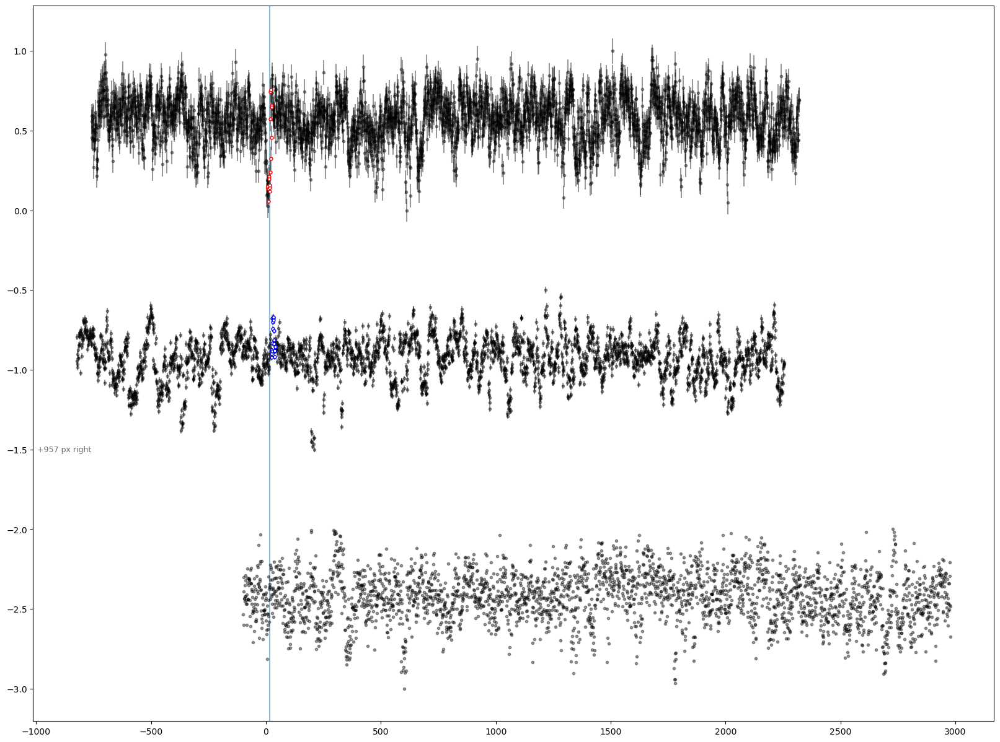

In [188]:
for i, row in our_cands.iterrows():
    
    indices = row['num_simultaneous_20_p1_time'] #space
    # print(indices)
    if len(indices)>1:
        # plot_lcs_together_images(i, indices[1],  df=concat)
        plot_lcs_simultaneous_with_spatial(i, indices, nosats, number=3, zoom=500)
        plt.show()
        # break

In [217]:
for i, row in our_cands.iterrows():
    
    indices = row['num_simultaneous_20_p1_time'] #space
    # print(indices)
    if len(indices)>1:
        # plot_lcs_together_images(i, indices[1],  df=concat)
        plot_lcs_simultaneous_with_spatial(i, indices, nosats, number=6, zoom=500)
        plt.show()
        break

NameError: name 'our_cands' is not defined

In [38]:
# from matplotlib.backends.backend_pdf import PdfPages

with PdfPages('/lustre/lrspec/ZTF_data/lightcurves/simultaneity_space.pdf') as pdf:
    for i, row in our_cands.iterrows():
        indices = row['num_simultaneous_20_p1_space']  # space
        if len(indices) > 1:
            plot_lcs_simultaneous_with_spatial(i, indices, nosats, number=3, zoom=500, time_adjusted=False)
            fig = plt.gcf()
            pdf.savefig(fig)
            plt.close(fig)

In [ ]:
150885 129490 40458 118511

In [218]:
for i, row in our_cands.iterrows():
    
    indices = row['num_simultaneous_20_p1_space'] #space
    print(indices)
    if len(indices)>1:
        # plot_lcs_together_images(i, indices[1],  df=concat)
        plot_lcs_simultaneous_with_spatial(i, indices, nosats, number=3, time_adjusted=False,zoom=500)
        plt.show()
        break

NameError: name 'our_cands' is not defined

In [219]:
for i, row in our_cands.iterrows():
    
    indices = row['num_simultaneous_20_p1_space'] #space
    print(indices)
    if len(indices)>1:
        # plot_lcs_together_images(i, indices[1],  df=concat)
        rff.plot_lcs_from_file(i, nosats, time_adjusted=False)
        plt.show()
        break

NameError: name 'our_cands' is not defined

In [168]:
df = nosats.copy()

In [170]:
df['diff_brightening_local'] = df['snr_local_brightening']-df['snr_local_brightening_filtered2']

In [67]:
our_cands.columns

Index(['Unnamed: 0.8', 'Unnamed: 0.7', 'Unnamed: 0.6', 'Unnamed: 0.5',
       'Unnamed: 0.4', 'Unnamed: 0.3', 'Unnamed: 0.2', 'Unnamed: 0.1',
       'Unnamed: 0', 'filename', 'quad', 'type', 'row_from_nn', 'col_from_nn',
       'detection_size', 'closest_x', 'closest_y', 'Diff',
       'original_cols_from_nn', 'original_rows_from_nn', 'detection_sizes',
       'modified_flag', 'original_types', 'snr_local_brightening',
       'snr_global_brightening', 'noise_local_brightening',
       'noise_global_brightening', 'local_average_outside_brightening',
       'height_brightening', 'FWHM_brightening', 'signal_local_brightening',
       'central_point_brightening', 'snr_local_dimming', 'snr_global_dimming',
       'noise_local_dimming', 'noise_global_dimming',
       'local_average_outside_dimming', 'height_dimming', 'FWHM_dimming',
       'signal_local_dimming', 'central_point_dimming', 'quadrant',
       'num_in_file_in_star', 'Band', 'snr_local_brightening_filtered2',
       'snr_global_b

(array([10.,  0.,  4.,  0.,  4.,  0.,  2.,  0.,  2.,  0.,  1.,  0.,  2.,
         0.,  0.,  2.,  0.,  2.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,
         0.,  0.,  0.,  1.]),
 array([ 1.        ,  1.46666667,  1.93333333,  2.4       ,  2.86666667,
         3.33333333,  3.8       ,  4.26666667,  4.73333333,  5.2       ,
         5.66666667,  6.13333333,  6.6       ,  7.06666667,  7.53333333,
         8.        ,  8.46666667,  8.93333333,  9.4       ,  9.86666667,
        10.33333333, 10.8       , 11.26666667, 11.73333333, 12.2       ,
        12.66666667, 13.13333333, 13.6       , 14.06666667, 14.53333333,
        15.        ]),
 <BarContainer object of 30 artists>)

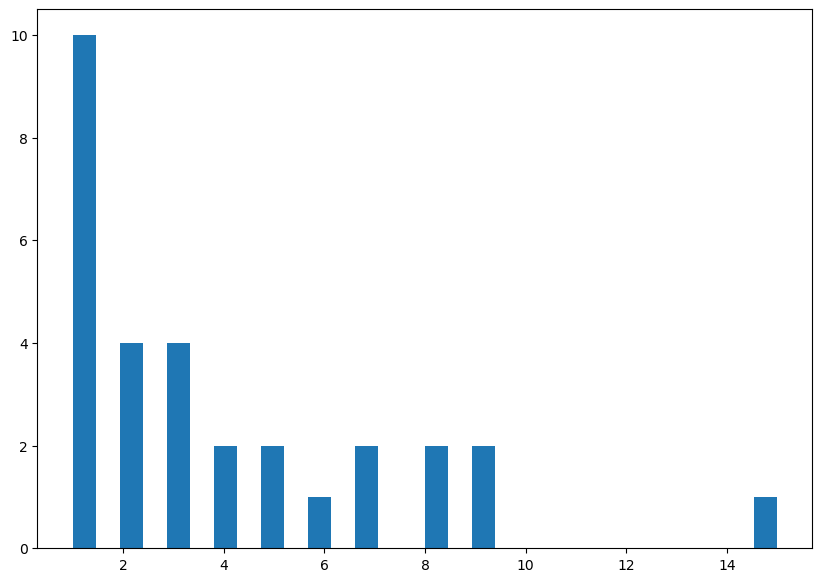

In [97]:
plt.hist(our_cands.sort_values('snr_local_filtered2', ascending=False)[:30]['num_in_file_in_star'], bins=30)
# plt.hist(our_cands['num_in_file_in_star'], bins=100)

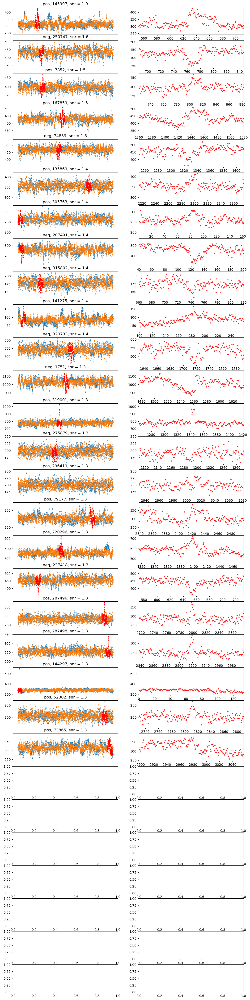

In [103]:
# df = concat2.sort_values('diff_brightening_local', ascending=False).drop(index=droplist) #biggest filt>original
# df = c[:30]
size = 160
new = our_cands[our_cands['num_in_file_in_star']<2]
df = new.sort_values('snr_local_filtered2', ascending=False)[:30]
figrows = 30
fig, ax = plt.subplots(figrows, 2, figsize=(7 * 1.8, figrows * 1.8))

for i, index in enumerate(df.index[:figrows].values):
    # print(index)
    tot, maxols = rff.get_tot_csv(df, index)
    ax[i,0].plot(tot, '.', ms=2, alpha=.8)
    tot_filt = rff.get_tot_csv_filtered_hap2(df, index)
    ax[i,0].plot(tot_filt, '.', ms=2, alpha=.8)
    ax[i,0].set_title(str(df.loc[index, "real_type_local"])+", "+str(df.loc[index, "concat_index_copy"])+", snr = "+f"{df.loc[index, 'snr_local_filtered2']:.1f}")
    ax[i,0].set_xticks([])
    ax[i,1].plot(tot, '.', ms=5, alpha=.8, c='red')
    try:
        if str(df.loc[index, "real_type_local"])=='pos':
            range1 = np.max([int(df.loc[index, 'central_point_brightening_filtere']-size//2), 0])
            range2 = np.min([int(df.loc[index, 'central_point_brightening_filtere']+size//2-1), len(tot)])
            xes = np.linspace(range1, range2, range2-range1+1)
            # print(range1, range2, len(tot), len(tot[range1:range2+1]))
            # print(len(xes))
            # print(xes)
            ax[i,1].set_xlim(range1, range2+1)
            ax[i,0].scatter(xes,tot[range1:range2+1],  s=3, alpha=.8, c='red', zorder=10)
        elif str(df.loc[index, "real_type_local"])=='neg':
            
            range1 = np.max([int(df.loc[index, 'central_point_dimming_filtere']-size//2), 0])
            range2 = np.min([int(df.loc[index, 'central_point_dimming_filtere']+size//2-1), len(tot)])
            # print(range1, range2, len(tot), len(tot[range1:range2+1]), len(xes))
            xes = np.linspace(range1, range2, range2-range1+1)
            # print(len(xes))
            # print(xes)
            ax[i,1].set_xlim(range1, range2+1)
            ax[i,0].scatter(xes,tot[range1:range2+1],  s=3, alpha=.8, c='red', zorder=10)
            
            # xes = np.linspace(df.loc[index, 'central_point_dimming_filtere']-size//2,df.loc[index, 'central_point_dimming_filtere']+size//2-1,2*(size//2))
            # # print(len(xes))
            # # print(xes)
            # ax[i,1].set_xlim(df.loc[index, 'central_point_dimming_filtere']-size//2, df.loc[index, 'central_point_dimming_filtere']+size//2)
            # ax[i,0].scatter(xes,tot[int(df.loc[index, 'central_point_dimming_filtere'])-size//2:int(df.loc[index, 'central_point_dimming_filtere'])+size//2],  s=15, alpha=.8, c='red', zorder=10)
    except ValueError:
        pass

In [ ]:
moresats = [195365, 291022, 163685, 326045, 272956, 306621, 22579, 
            79095
,262472
293337
298575
154765,
181844
272947
329013
176927
192302
179370
52316
131777
117765
82320
224886
131780

/home/3155/rwe/review_findings_functions.py:2257: UserWarning: Attempting to set identical low and high ylims makes transformation singular; automatically expanding.
  ax[i, j].imshow(stamp, vmax=clim)
/home/3155/rwe/review_findings_functions.py:2257: UserWarning: Attempting to set identical low and high xlims makes transformation singular; automatically expanding.
  ax[i, j].imshow(stamp, vmax=clim)


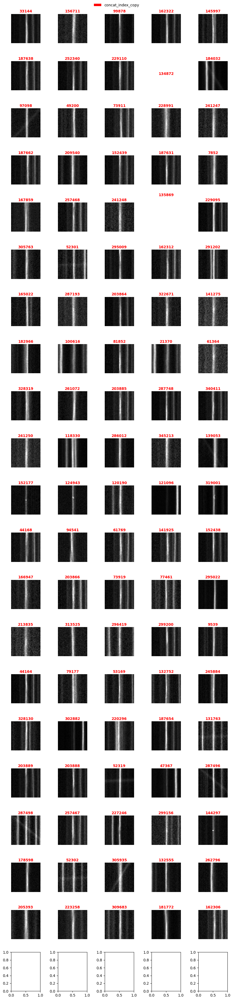

In [155]:
rff.inspect_df_w_stamp_color(nosats.sort_values('snr_local_brightening_filtered2', ascending=False)[:100], titlecol=['concat_index_copy'], imgsize=20)

In [176]:
for number, (i, row) in enumerate(final_df[final_df['random_forest_result']==1].iterrows()):
    final_df.loc[i,'just_a_number']=number

In [178]:
final_df

,Unnamed: 0.5,Unnamed: 0.4,Unnamed: 0.3,Unnamed: 0.2,Unnamed: 0.1,Unnamed: 0,filename,quad,type,row_from_nn,...,noise_global_dimming_f3,height_dimming_f3,FWHM_dimming_f3,signal_local_dimming_f3,central_point_dimming_f3,concat_index_copy,snr,real_type,random_forest_result,just_a_number
345520,345520,345520,345520,345520,48,86,ztf_20221020141806_000686_zi_c14_x_0005.,4,neg,64.083333,...,87.429045,-63.207286,3.0,11.932270,70.0,345520,5.174970,pos,1.0,0.0
299239,299239,299239,299239,299239,47,75,ztf_20221020141806_000686_zi_c14_x_0014.,4,both,2984.789474,...,71.044968,-25.396284,1.0,5.039473,2994.0,299239,5.053696,pos,1.0,1.0
43719,43719,43719,43719,43719,22,57,ztf_20221020148032_000686_zg_c07_x_0011.,1,pos,2835.750000,...,28.511955,-100.053308,3.0,14.702464,2838.0,43719,4.221054,pos,1.0,2.0
69095,69095,69095,69095,69095,53,84,ztf_20221020141806_000686_zi_c14_x_0006.,4,pos,2991.888889,...,75.503975,-148.921742,7.0,28.197722,2999.0,69095,4.180017,pos,1.0,3.0
310766,310766,310766,310766,310766,3,13,ztf_20221020138241_000686_zi_c15_x_0014.,4,pos,1772.000000,...,66.892327,-336.358806,10.0,49.864441,1764.0,310766,3.916689,neg,1.0,4.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
187642,187642,187642,187642,187642,21,32,ztf_20221020141806_000686_zi_c14_x_0019.,4,pos,1184.000000,...,64.649777,-41.130346,6.0,20.254659,1193.0,187642,2.126600,pos,1.0,83.0
167378,167378,167378,167378,167378,18,15,ztf_20221020141806_000686_zi_c14_x_0001.,4,both,462.051724,...,91.312529,-144.159698,5.0,21.381058,455.0,167378,2.125921,neg,1.0,84.0
203084,203084,203084,203084,203084,132,429,ztf_20221020148032_000686_zg_c01_x_0019.,1,neg,2905.600000,...,66.406649,-245.687730,3.0,27.904288,2914.0,203084,2.119100,neg,1.0,85.0
42066,42066,42066,42066,42066,8,26,ztf_20221020294271_000449_zr_c14_x_0001.,4,pos,1153.727273,...,67.818329,-336.429542,8.0,45.593620,1143.0,42066,2.117701,neg,0.0,NaN


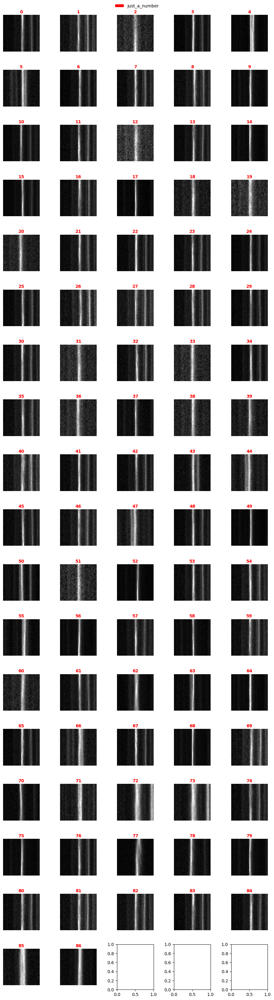

In [179]:

rff.inspect_df_w_stamp_color(final_df[final_df['random_forest_result']==1], titlecol=['just_a_number'], imgsize=20)

In [186]:
name = 'lightcurve_'+df_row['filename'][:-1]+'_'+str(df_row['quadrant'])+'_'+f'{int(df_row["closest_x"]):04}'+'_'+f'{int(df_row["closest_y"]):04}'+'.csv'

In [187]:
name

'lightcurve_ztf_20221020297847_000449_zr_c10_x_0014_4_0523_0694.csv'

In [185]:
df_row = final_df[final_df['just_a_number']==77].iloc[0]

In [15]:
importlib.reload(rff)

<module 'review_findings_functions' from '/home/3155/rwe/review_findings_functions.py'>

In [18]:
concat_filtered_with_rf.shape

(347424, 81)

In [16]:
rff.add_rf_lightcurves(concat_filtered_with_rf[:10])

,Unnamed: 0.7,Unnamed: 0.6,Unnamed: 0.5,Unnamed: 0.4,Unnamed: 0.3,Unnamed: 0.2,Unnamed: 0.1,Unnamed: 0,filename,quad,...,height_dimming_f3,FWHM_dimming_f3,signal_local_dimming_f3,central_point_dimming_f3,snr_local,snr_global,real_type_local,real_type_global,distance_from_start,random_forest_result
0,0,0,0,0,0,0,0,0,ztf_20221020141806_000686_zi_c11_x_0017.,4,...,-356.194423,3.0,30.026146,690.0,0.120616,0.145088,pos,pos,138.500000,0.0
1,1,1,1,1,1,1,1,3,ztf_20221020141806_000686_zi_c11_x_0017.,4,...,-472.117198,5.0,42.164851,1160.0,0.163725,0.148208,neg,neg,-338.312500,0.0
2,2,2,2,2,2,2,2,4,ztf_20221020141806_000686_zi_c11_x_0017.,4,...,-117.115640,1.0,10.821998,2070.0,0.507125,0.409946,pos,pos,-1255.173913,0.0
3,3,3,3,3,3,3,3,6,ztf_20221020141806_000686_zi_c11_x_0017.,4,...,-680.929089,6.0,54.227081,2461.0,0.190395,0.198984,pos,pos,-1632.625000,0.0
4,4,4,4,4,4,4,4,7,ztf_20221020141806_000686_zi_c11_x_0017.,4,...,-279.760163,1.0,16.726032,2562.0,0.191027,0.187296,neg,neg,-1736.500000,0.0
5,5,5,5,5,5,5,5,11,ztf_20221020141806_000686_zi_c11_x_0017.,4,...,-314.219790,1.0,17.726246,2927.0,0.192855,0.158871,pos,pos,-2100.125000,0.0
6,6,6,6,6,6,6,6,5,ztf_20221020141806_000686_zi_c11_x_0017.,4,...,-102.738819,1.0,10.136016,2218.0,0.517587,0.489895,neg,neg,-1032.500000,0.0
7,7,7,7,7,7,7,7,14,ztf_20221020141806_000686_zi_c11_x_0017.,4,...,-167.020450,7.0,29.369915,287.0,0.419343,0.419690,neg,neg,901.000000,0.0
8,8,8,8,8,8,8,0,19,ztf_20221020148032_000686_zg_c14_x_0017.,1,...,-490.685342,3.0,36.297812,1852.0,0.270055,0.283123,neg,neg,-56.000000,0.0
9,9,9,9,9,9,9,1,25,ztf_20221020148032_000686_zg_c14_x_0017.,1,...,-326.685203,2.0,24.449893,2573.0,0.199293,0.205830,neg,neg,-788.850000,0.0


In [10]:
concat_filtered_with_rf.loc[100616, 'filename']

'ztf_20221020148032_000686_zg_c04_x_0028.'

In [8]:
concat_filtered_with_rf.loc[21370, 'filename']

'ztf_20221020148032_000686_zg_c04_x_0029.'

In [11]:
concat_filtered_with_rf.loc[31685, 'filename']

'ztf_20221020141806_000686_zi_c01_x_0028.'

In [13]:
concat_filtered_with_rf.loc[108935, 'filename']

'ztf_20221020141806_000686_zi_c01_x_0029.'

In [15]:
concat_filtered_with_rf.loc[21370, 'quad']

2

In [33]:
fpath = '/lustre/lrspec/ZTF_data/2022/1020/'
quad = concat_filtered_with_rf.loc[100616, 'quad']
fname = concat_filtered_with_rf.loc[100616, 'filename']+'fits.fz'
path = fpath + fname
hdul = fits.open(path)
file1_array = hdul[quad].data

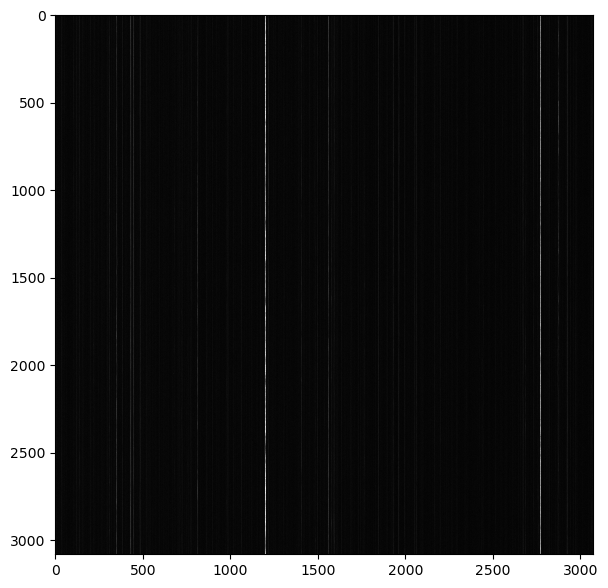

In [22]:
plt.imshow(file1_array)

In [30]:
concat_filtered_with_rf

,Unnamed: 0.9,Unnamed: 0.8,Unnamed: 0.7,Unnamed: 0.6,Unnamed: 0.5,Unnamed: 0.4,Unnamed: 0.3,Unnamed: 0.2,Unnamed: 0.1,Unnamed: 0,...,height_dimming_f3,FWHM_dimming_f3,signal_local_dimming_f3,central_point_dimming_f3,snr_local,snr_global,real_type_local,real_type_global,distance_from_start,random_forest_result
0,0,0,0,0,0,0,0,0,0,0,...,-356.194423,3.0,30.026146,690.0,0.120616,0.145088,pos,pos,138.500000,0.0
1,1,1,1,1,1,1,1,1,1,3,...,-472.117198,5.0,42.164851,1160.0,0.163725,0.148208,neg,neg,-338.312500,0.0
2,2,2,2,2,2,2,2,2,2,4,...,-117.115640,1.0,10.821998,2070.0,0.507125,0.409946,pos,pos,-1255.173913,0.0
3,3,3,3,3,3,3,3,3,3,6,...,-680.929089,6.0,54.227081,2461.0,0.190395,0.198984,pos,pos,-1632.625000,0.0
4,4,4,4,4,4,4,4,4,4,7,...,-279.760163,1.0,16.726032,2562.0,0.191027,0.187296,neg,neg,-1736.500000,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
347419,347419,347419,347419,347419,347419,347419,347419,347419,49,77,...,-198.335604,2.0,19.493971,833.0,0.377672,0.401030,neg,neg,625.500000,0.0
347420,347420,347420,347420,347420,347420,347420,347420,347420,50,34,...,-89.109350,3.0,13.851402,1253.0,0.918655,0.889413,neg,neg,-388.214286,0.0
347421,347421,347421,347421,347421,347421,347421,347421,347421,51,39,...,-34.856257,1.0,5.903919,1338.0,0.845833,0.911684,pos,pos,-491.156250,0.0
347422,347422,347422,347422,347422,347422,347422,347422,347422,0,0,...,-709.111444,3.0,41.629913,834.0,0.283822,0.246317,pos,pos,1227.142857,0.0


In [36]:
np.max(file2_array), np.min(file2_array)

(1666.3748, 148.39995)

Text(0.5, 1.0, 'ztf_20221020148032_000686_zg_c04_x_0029.fits.fz')

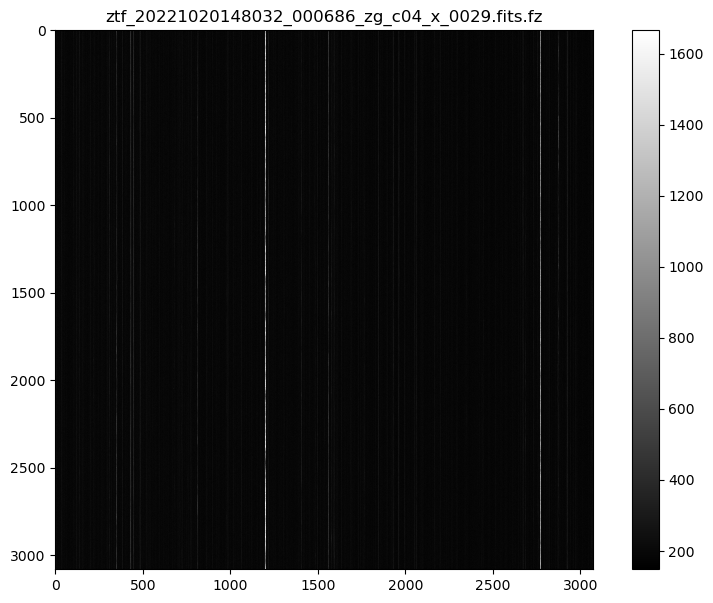

In [126]:
plt.imshow(file2_array)
plt.colorbar()
plt.title(fname2)

Text(0.5, 1.0, 'Difference')

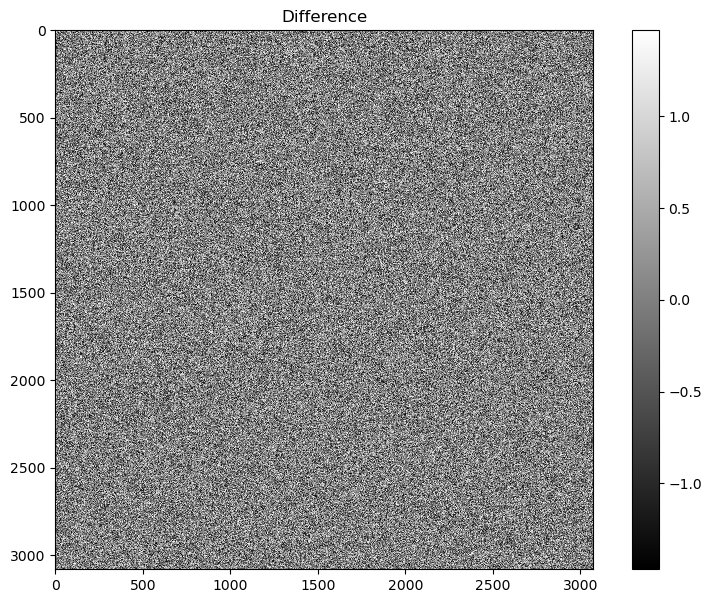

In [119]:
fpath = '/lustre/lrspec/ZTF_data/2022/1020/'
quad2 = concat_filtered_with_rf.loc[21370, 'quad']
fname2 = concat_filtered_with_rf.loc[21370, 'filename']+'fits.fz'
path2 = fpath + fname2
hdul2 = fits.open(path2)
file2_array = hdul2[quad2].data
plt.imshow(file2_array- file1_array)
plt.colorbar()
plt.title("Difference")

In [40]:
rowindex = 21370
hap=2
lightcurve_path = '/lustre/lrspec/ZTF_data/lightcurves/1020/'
df_row = concat_filtered_with_rf.loc[rowindex]
lc_filename = 'lightcurve_'+df_row['filename'][:-1]+'_'+str(df_row['quadrant'])+'_'+f'{int(df_row["closest_x"]):04}'+'_'+f'{int(df_row["closest_y"]):04}'+'.csv'

lightcurve_path = '/lustre/lrspec/ZTF_data/lightcurves/1020/'
lc_df = pd.read_csv(lightcurve_path+lc_filename)
tot = lc_df['flux_hap_'+str(hap)]

In [37]:
rowindex2 = 100616
hap=2
lightcurve_path = '/lustre/lrspec/ZTF_data/lightcurves/1020/'
df_row2 = concat_filtered_with_rf.loc[rowindex2]
lc_filename2 = 'lightcurve_'+df_row2['filename'][:-1]+'_'+str(df_row2['quadrant'])+'_'+f'{int(df_row2["closest_x"]):04}'+'_'+f'{int(df_row2["closest_y"]):04}'+'.csv'

lightcurve_path = '/lustre/lrspec/ZTF_data/lightcurves/1020/'
lc_df2 = pd.read_csv(lightcurve_path+lc_filename2)
tot2 = lc_df2['flux_hap_'+str(hap)]

In [38]:
np.max(tot2)

495.03662109375

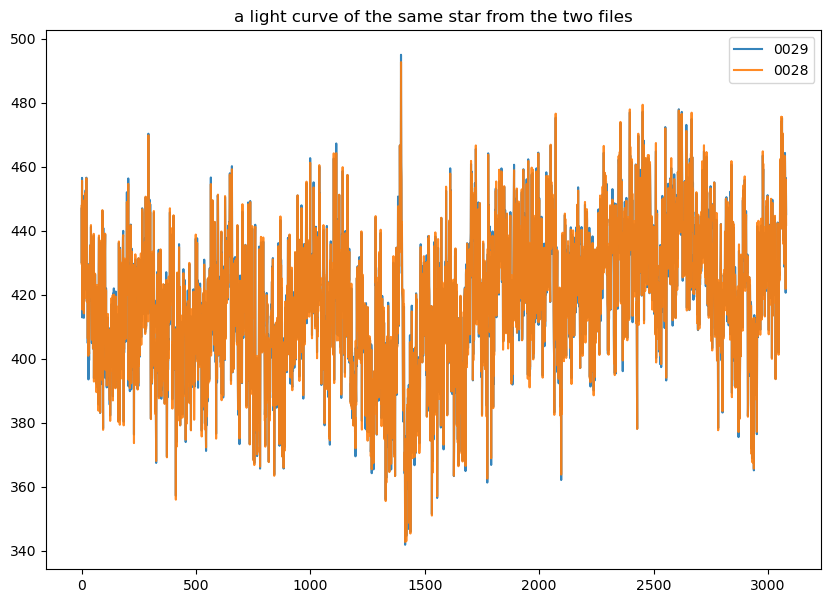

In [123]:
# plt.plot(tot, alpha=.5)
plt.plot(tot2, alpha=.9, label = '0029')
plt.plot(tot, alpha=.9, label = '0028')
plt.title("a light curve of the same star from the two files")
plt.legend()

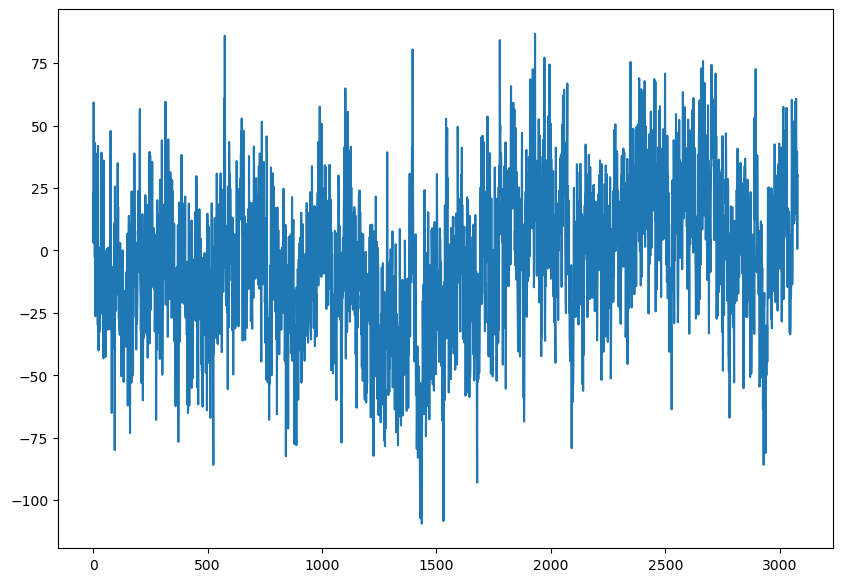

In [48]:
plt.plot(tot-tot3)

In [44]:
rowindex2 = 100616
hap=2
lightcurve_path = '/lustre/lrspec/ZTF_data/lightcurves/1020/'
df_row2 = concat_filtered_with_rf.loc[rowindex2]
lc_filename2 = 'lightcurve_'+'ztf_20221020148032_000686_zg_c04_x_0027'+'_'+str(df_row2['quadrant'])+'_'+f'{int(df_row2["closest_x"]):04}'+'_'+f'{int(df_row2["closest_y"]):04}'+'.csv'

lightcurve_path = '/lustre/lrspec/ZTF_data/lightcurves/1020/'
lc_df2 = pd.read_csv(lightcurve_path+lc_filename2)
tot3 = lc_df2['flux_hap_'+str(hap)]

In [88]:
def match_stars(df):
    brightness_ranking = np.zeros(len(df))
    xy_path = "/lustre/lrspec/ZTF_data/corrected_coordinates/xy_arrays/"
    i=0
    for index, rrow in df.iterrows():
        quad = str(rrow['quad'])
        # print(df.loc[index,'filename'][:35])
        xy_file = xy_path+rrow['filename'][:35]+quad+".fits"
        # print(xy_file)
        with fits.open(xy_file) as hdul_xy:
            target_x = rrow["closest_x"]
            # print(xy_file)
            data = hdul_xy[1].data  
            stored_x = data["X"][:25]  # Column "X"
            stored_y = data["Y"][:25]
            closest_idx = np.argmin(np.abs(stored_x - target_x))
            brightness_ranking[i]= closest_idx
            # print(closest_idx)
            # print(df.loc[index]['brightness_ranking'])
            i+=1 #yes there is a better way to do this
    df['brightness_ranking'] = brightness_ranking
    return df

Text(0.5, 0, 'brightness ranking')

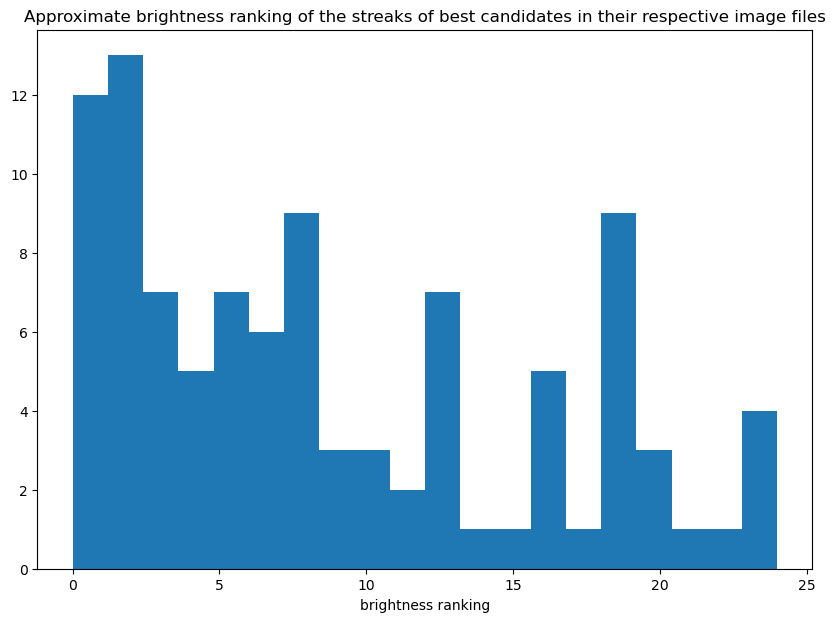

In [98]:
plt.hist(final_df_rfgood_filtered['brightness_ranking'], bins=20)
plt.title("Approximate brightness ranking of the streaks of best candidates in their respective image files")
plt.xlabel("brightness ranking")

In [93]:
np.max(final_df_rfgood_filtered['Diff'])

4.0

In [99]:
rf_gone

,Unnamed: 0.9,Unnamed: 0.8,Unnamed: 0.7,Unnamed: 0.6,Unnamed: 0.5,Unnamed: 0.4,Unnamed: 0.3,Unnamed: 0.2,Unnamed: 0.1,Unnamed: 0,...,height_dimming_f3,FWHM_dimming_f3,signal_local_dimming_f3,central_point_dimming_f3,snr_local,snr_global,real_type_local,real_type_global,distance_from_start,random_forest_result
0,0,0,0,0,0,0,0,0,0,0,...,-356.194423,3.0,30.026146,690.0,0.120616,0.145088,pos,pos,138.500000,0.0
1,1,1,1,1,1,1,1,1,1,3,...,-472.117198,5.0,42.164851,1160.0,0.163725,0.148208,neg,neg,-338.312500,0.0
2,2,2,2,2,2,2,2,2,2,4,...,-117.115640,1.0,10.821998,2070.0,0.507125,0.409946,pos,pos,-1255.173913,0.0
3,3,3,3,3,3,3,3,3,3,6,...,-680.929089,6.0,54.227081,2461.0,0.190395,0.198984,pos,pos,-1632.625000,0.0
4,4,4,4,4,4,4,4,4,4,7,...,-279.760163,1.0,16.726032,2562.0,0.191027,0.187296,neg,neg,-1736.500000,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
347419,347419,347419,347419,347419,347419,347419,347419,347419,49,77,...,-198.335604,2.0,19.493971,833.0,0.377672,0.401030,neg,neg,625.500000,0.0
347420,347420,347420,347420,347420,347420,347420,347420,347420,50,34,...,-89.109350,3.0,13.851402,1253.0,0.918655,0.889413,neg,neg,-388.214286,0.0
347421,347421,347421,347421,347421,347421,347421,347421,347421,51,39,...,-34.856257,1.0,5.903919,1338.0,0.845833,0.911684,pos,pos,-491.156250,0.0
347422,347422,347422,347422,347422,347422,347422,347422,347422,0,0,...,-709.111444,3.0,41.629913,834.0,0.283822,0.246317,pos,pos,1227.142857,0.0


In [100]:
match_stars(rf_gone)

/tmp/ipykernel_39794/1079576715.py:21: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df['brightness_ranking'] = brightness_ranking


,Unnamed: 0.9,Unnamed: 0.8,Unnamed: 0.7,Unnamed: 0.6,Unnamed: 0.5,Unnamed: 0.4,Unnamed: 0.3,Unnamed: 0.2,Unnamed: 0.1,Unnamed: 0,...,FWHM_dimming_f3,signal_local_dimming_f3,central_point_dimming_f3,snr_local,snr_global,real_type_local,real_type_global,distance_from_start,random_forest_result,brightness_ranking
0,0,0,0,0,0,0,0,0,0,0,...,3.0,30.026146,690.0,0.120616,0.145088,pos,pos,138.500000,0.0,0.0
1,1,1,1,1,1,1,1,1,1,3,...,5.0,42.164851,1160.0,0.163725,0.148208,neg,neg,-338.312500,0.0,0.0
2,2,2,2,2,2,2,2,2,2,4,...,1.0,10.821998,2070.0,0.507125,0.409946,pos,pos,-1255.173913,0.0,0.0
3,3,3,3,3,3,3,3,3,3,6,...,6.0,54.227081,2461.0,0.190395,0.198984,pos,pos,-1632.625000,0.0,0.0
4,4,4,4,4,4,4,4,4,4,7,...,1.0,16.726032,2562.0,0.191027,0.187296,neg,neg,-1736.500000,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
347419,347419,347419,347419,347419,347419,347419,347419,347419,49,77,...,2.0,19.493971,833.0,0.377672,0.401030,neg,neg,625.500000,0.0,2.0
347420,347420,347420,347420,347420,347420,347420,347420,347420,50,34,...,3.0,13.851402,1253.0,0.918655,0.889413,neg,neg,-388.214286,0.0,12.0
347421,347421,347421,347421,347421,347421,347421,347421,347421,51,39,...,1.0,5.903919,1338.0,0.845833,0.911684,pos,pos,-491.156250,0.0,12.0
347422,347422,347422,347422,347422,347422,347422,347422,347422,0,0,...,3.0,41.629913,834.0,0.283822,0.246317,pos,pos,1227.142857,0.0,0.0


In [2]:
rf_gone = pd.read_csv('/lustre/lrspec/ZTF_data/science_extractions/1020april26/average/rf_gone_with_brightness_ranking')

In [3]:
rf_gone

,Unnamed: 0.10,Unnamed: 0.9,Unnamed: 0.8,Unnamed: 0.7,Unnamed: 0.6,Unnamed: 0.5,Unnamed: 0.4,Unnamed: 0.3,Unnamed: 0.2,Unnamed: 0.1,...,FWHM_dimming_f3,signal_local_dimming_f3,central_point_dimming_f3,snr_local,snr_global,real_type_local,real_type_global,distance_from_start,random_forest_result,brightness_ranking
0,0,0,0,0,0,0,0,0,0,0,...,3.0,30.026146,690.0,0.120616,0.145088,pos,pos,138.500000,0.0,0.0
1,1,1,1,1,1,1,1,1,1,1,...,5.0,42.164851,1160.0,0.163725,0.148208,neg,neg,-338.312500,0.0,0.0
2,2,2,2,2,2,2,2,2,2,2,...,1.0,10.821998,2070.0,0.507125,0.409946,pos,pos,-1255.173913,0.0,0.0
3,3,3,3,3,3,3,3,3,3,3,...,6.0,54.227081,2461.0,0.190395,0.198984,pos,pos,-1632.625000,0.0,0.0
4,4,4,4,4,4,4,4,4,4,4,...,1.0,16.726032,2562.0,0.191027,0.187296,neg,neg,-1736.500000,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
342428,347419,347419,347419,347419,347419,347419,347419,347419,347419,49,...,2.0,19.493971,833.0,0.377672,0.401030,neg,neg,625.500000,0.0,2.0
342429,347420,347420,347420,347420,347420,347420,347420,347420,347420,50,...,3.0,13.851402,1253.0,0.918655,0.889413,neg,neg,-388.214286,0.0,12.0
342430,347421,347421,347421,347421,347421,347421,347421,347421,347421,51,...,1.0,5.903919,1338.0,0.845833,0.911684,pos,pos,-491.156250,0.0,12.0
342431,347422,347422,347422,347422,347422,347422,347422,347422,347422,0,...,3.0,41.629913,834.0,0.283822,0.246317,pos,pos,1227.142857,0.0,0.0


In [104]:
rf_gone.to_csv('/lustre/lrspec/ZTF_data/science_extractions/1020april26/average/rf_gone_with_brightness_ranking')

Text(0.5, 0, 'brightness ranking')

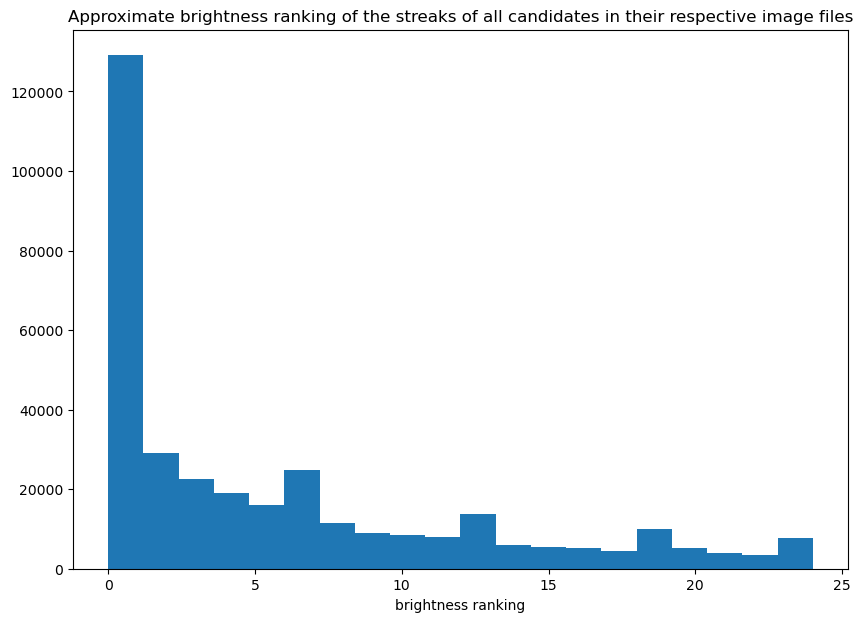

In [101]:
plt.hist(rf_gone['brightness_ranking'], bins=20)
plt.title("Approximate brightness ranking of the streaks of all candidates in their respective image files")
plt.xlabel("brightness ranking")

In [112]:
local_or_global='local'
for i, row in nostartingedges.iterrows():
    if row['real_type_'+local_or_global]=='pos':
        nostartingedges.loc[i, 'snr_local_filtered2'] = nostartingedges.loc[i, 'snr_local_brightening_filtered2']
    else:
        nostartingedges.loc[i, 'snr_local_filtered2'] = nostartingedges.loc[i, 'snr_local_dimming_filtered2']


In [214]:
local_or_global='global'
for i, row in final_df_rfgood_filtered.iterrows():
    if row['real_type_'+local_or_global]=='pos':
        final_df_rfgood_filtered.loc[i, 'snr_global_filtered2'] = final_df_rfgood_filtered.loc[i, 'snr_global_brightening_filtered2']
    else:
        final_df_rfgood_filtered.loc[i, 'snr_global_filtered2'] = final_df_rfgood_filtered.loc[i, 'snr_global_dimming_filtered2']


In [215]:
final_df_rfgood_filtered

,Unnamed: 0.10,Unnamed: 0.9,Unnamed: 0.8,Unnamed: 0.7,Unnamed: 0.6,Unnamed: 0.5,Unnamed: 0.4,Unnamed: 0.3,Unnamed: 0.2,Unnamed: 0.1,...,snr_global,real_type_local,real_type_global,distance_from_start,random_forest_result,brightness_ranking,concat_index_copy,snr_local_filtered2,central_point,snr_global_filtered2
335350,340170,340170,340170,340170,340170,340170,340170,340170,340170,0,...,1.686088,neg,neg,2764.500000,0.0,0.0,340170,1.991304,74.0,1.431282
108222,109774,109774,109774,109774,109774,109774,109774,109774,109774,1,...,1.370316,neg,neg,-696.750000,0.0,14.0,109774,1.926008,2153.0,1.597983
143982,145997,145997,145997,145997,145997,145997,145997,145997,145997,4,...,1.394781,pos,pos,-149.428571,0.0,18.0,145997,1.911613,632.0,1.413040
74226,75263,75263,75263,75263,75263,75263,75263,75263,75263,27,...,1.798457,neg,neg,-370.750000,0.0,5.0,75263,1.748513,1843.0,1.676606
247244,250747,250747,250747,250747,250747,250747,250747,250747,250747,0,...,1.468635,neg,neg,-24.500000,0.0,3.0,250747,1.644846,766.0,1.384127
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
274863,278819,278819,278819,278819,278819,278819,278819,278819,278819,40,...,0.967729,pos,pos,1026.000000,0.0,9.0,278819,1.242029,431.0,1.112673
115079,116731,116731,116731,116731,116731,116731,116731,116731,116731,39,...,0.880168,neg,neg,1328.000000,0.0,11.0,116731,1.241657,52.0,1.079102
272353,276294,276294,276294,276294,276294,276294,276294,276294,276294,8,...,1.078894,pos,pos,1474.835784,0.0,6.0,276294,1.241553,993.0,1.094179
105226,106710,106710,106710,106710,106710,106710,106710,106710,106710,2,...,1.235634,pos,pos,-98.333333,0.0,11.0,106710,1.237331,359.0,1.207385


In [22]:
nosats

,Unnamed: 0.10,Unnamed: 0.9,Unnamed: 0.8,Unnamed: 0.7,Unnamed: 0.6,Unnamed: 0.5,Unnamed: 0.4,Unnamed: 0.3,Unnamed: 0.2,Unnamed: 0.1,...,signal_local_dimming_f3,central_point_dimming_f3,snr_local,snr_global,real_type_local,real_type_global,distance_from_start,random_forest_result,brightness_ranking,concat_index_copy
0,0,0,0,0,0,0,0,0,0,0,...,30.026146,690.0,0.120616,0.145088,pos,pos,138.500000,0.0,0.0,0
1,1,1,1,1,1,1,1,1,1,1,...,42.164851,1160.0,0.163725,0.148208,neg,neg,-338.312500,0.0,0.0,1
2,2,2,2,2,2,2,2,2,2,2,...,10.821998,2070.0,0.507125,0.409946,pos,pos,-1255.173913,0.0,0.0,2
3,3,3,3,3,3,3,3,3,3,3,...,54.227081,2461.0,0.190395,0.198984,pos,pos,-1632.625000,0.0,0.0,3
4,4,4,4,4,4,4,4,4,4,4,...,16.726032,2562.0,0.191027,0.187296,neg,neg,-1736.500000,0.0,0.0,4
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
342428,347419,347419,347419,347419,347419,347419,347419,347419,347419,49,...,19.493971,833.0,0.377672,0.401030,neg,neg,625.500000,0.0,2.0,347419
342429,347420,347420,347420,347420,347420,347420,347420,347420,347420,50,...,13.851402,1253.0,0.918655,0.889413,neg,neg,-388.214286,0.0,12.0,347420
342430,347421,347421,347421,347421,347421,347421,347421,347421,347421,51,...,5.903919,1338.0,0.845833,0.911684,pos,pos,-491.156250,0.0,12.0,347421
342431,347422,347422,347422,347422,347422,347422,347422,347422,347422,0,...,41.629913,834.0,0.283822,0.246317,pos,pos,1227.142857,0.0,0.0,347422


In [56]:
%matplotlib inline

In [76]:
np.max(nostartingedges['snr_local_denoised'])

40.275451170899295

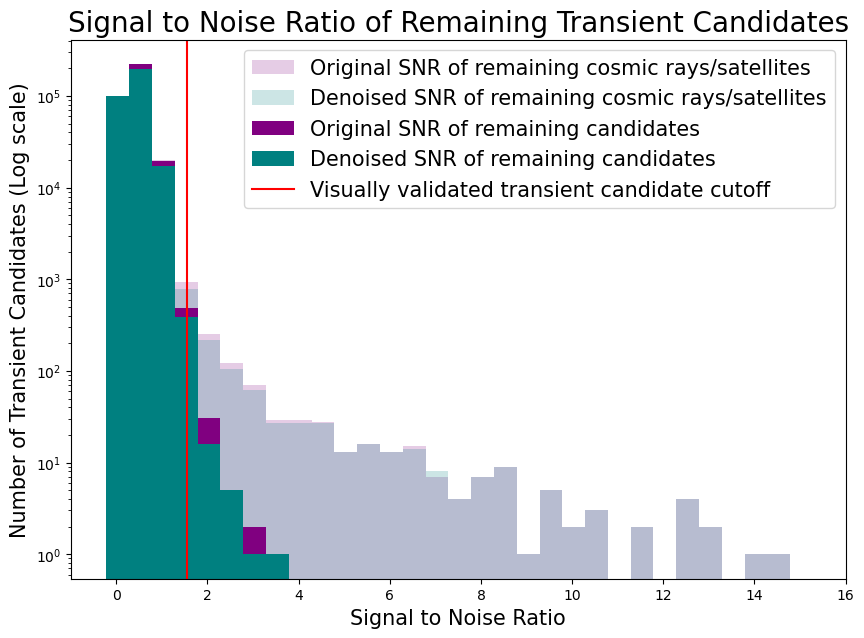

In [74]:
# plt.hist(nostartingedges['snr_global'],  bins=20, label='unfiltered SNR global', alpha=.8)
binwidth = .5
thebins = np.arange(np.min(nostartingedges['snr_local_denoised']), np.max(nostartingedges['snr_local']) + binwidth, binwidth)
plt.hist(nostartingedges['snr_local'],  bins=thebins, label='Original SNR of remaining cosmic rays/satellites', alpha=.2, color='purple')
plt.hist(nostartingedges['snr_local_denoised'],  bins=thebins, label='Denoised SNR of remaining cosmic rays/satellites', alpha=.2, color = 'teal')
plt.hist(nosats['snr_local'],  bins=thebins, label='Original SNR of remaining candidates', alpha=1, color='purple')
plt.hist(nosats['snr_local_denoised'],  bins=thebins, label='Denoised SNR of remaining candidates', alpha=1, color = 'teal')
plt.axvline(1.548, label="Visually validated transient candidate cutoff", c='red')

plt.yscale('log')
plt.legend(fontsize=15)
plt.title("Signal to Noise Ratio of Remaining Transient Candidates", fontsize=20)
plt.xlabel("Signal to Noise Ratio", fontsize=15)
plt.ylabel('Number of Transient Candidates (Log scale)', fontsize=15)
plt.xlim(-1,16)
plt.show()

In [52]:
final_df.loc[65885]

Unnamed: 0.10                            65885
Unnamed: 0.9                             65885
Unnamed: 0.8                             65885
Unnamed: 0.7                             65885
Unnamed: 0.6                             65885
                                     ...      
concat_index_copy                        65885
snr_local_denoised                    1.859924
central_point                           1844.0
num_simultaneous_20_p1_space           [65885]
num_simultaneous_20_p1_time     [65885, 65855]
Name: 65885, Length: 106, dtype: object

In [57]:
relevant = nosats.loc[[65885, 65855]]

In [53]:
path = '/lustre/lrspec/ZTF_data/2022/1020/'
with fits.open(path+final_df.loc[65885,'filename']+'fits.fz') as hdul:
    image = hdul[final_df.loc[65885,'quad']].data

In [60]:
relevant.columns

Index(['Unnamed: 0.10', 'Unnamed: 0.9', 'Unnamed: 0.8', 'Unnamed: 0.7',
       'Unnamed: 0.6', 'Unnamed: 0.5', 'Unnamed: 0.4', 'Unnamed: 0.3',
       'Unnamed: 0.2', 'Unnamed: 0.1',
       ...
       'snr_global_dimming_denoised', 'noise_local_dimming_denoised',
       'noise_global_dimming_denoised',
       'local_average_outside_dimming_denoised', 'height_dimming_denoised',
       'FWHM_dimming_denoised', 'signal_local_dimming_denoised',
       'central_point_dimming_denoised', 'concat_index_copy',
       'snr_local_denoised'],
      dtype='object', length=103)

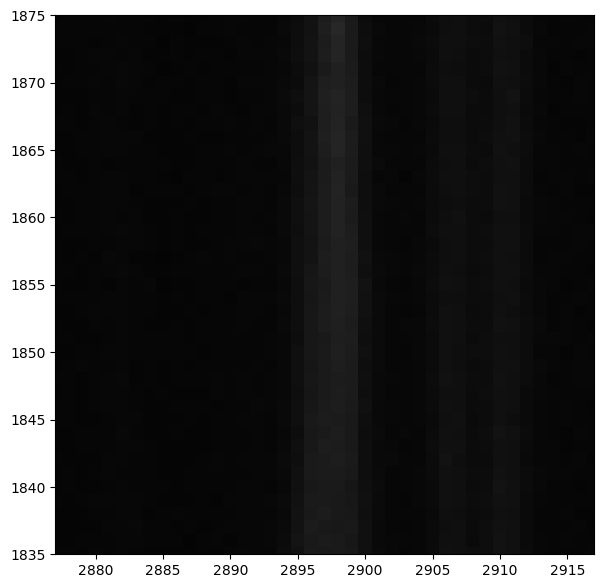

In [64]:
index = 65885
xlim = (relevant.loc[index,'closest_x']-20,relevant.loc[index,'closest_x']+20)
ylim = (relevant.loc[index,'central_point_brightening']-20,relevant.loc[index,'central_point_brightening']+20)
plt.imshow(image)
plt.xlim(xlim)
plt.ylim(ylim)
plt.show()

In [ ]:
(1544.0, 1584.0)

In [75]:
ylim

(2846.0, 2886.0)

In [76]:
small_image = image[2846:2886,1544:1584]

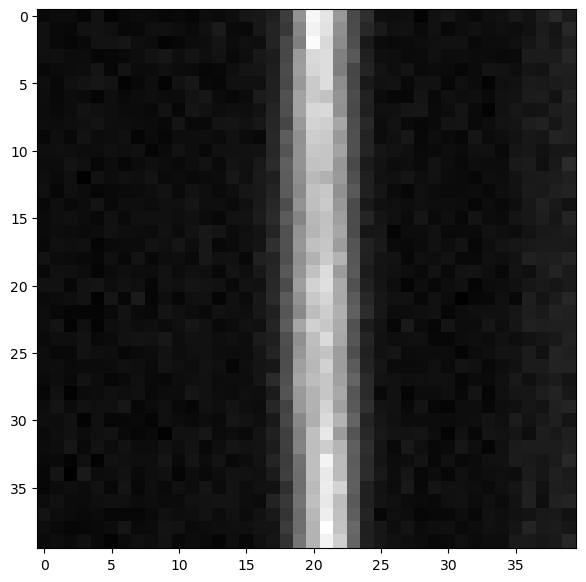

In [77]:
plt.imshow(small_image)

(array([1176.,  186.,   27.,   50.,    9.,   33.,   34.,   48.,   26.,
          11.]),
 array([164.1986084 , 187.12533569, 210.05206299, 232.97880554,
        255.90553284, 278.83227539, 301.75900269, 324.68572998,
        347.61245728, 370.53918457, 393.46591187]),
 <BarContainer object of 10 artists>)

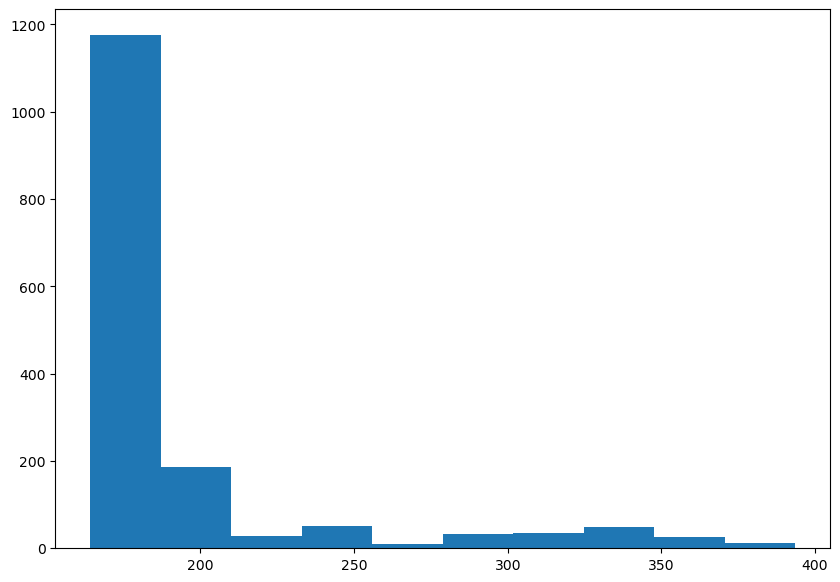

In [78]:
plt.hist(small_image.flatten())

In [70]:
relevant.loc[65855,'closest_x']-20

1544.0

In [82]:
xlim

(2877.0, 2917.0)

In [83]:
ylim

(1835.0, 1875.0)

In [81]:
index = 65885
xlim = (relevant.loc[index,'closest_x']-20,relevant.loc[index,'closest_x']+20)
ylim = (relevant.loc[index,'central_point_brightening']-20,relevant.loc[index,'central_point_brightening']+20)
# plt.imshow(small_image, clim=[200,400])
# plt.xlim(xlim)
# plt.ylim(ylim)
# plt.show()

In [85]:
small_image_2 = image[1835:1875,2877:2917]

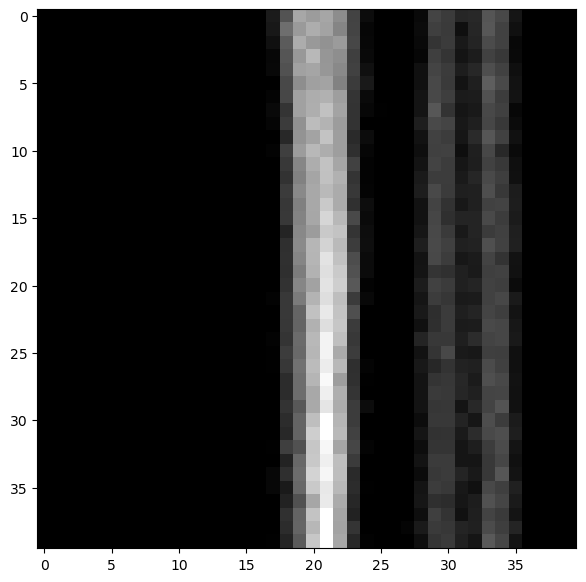

In [90]:
# index = 65855
# xlim = (relevant.loc[index,'closest_x']-20,relevant.loc[index,'closest_x']+20)
# ylim = (relevant.loc[index,'central_point_brightening']-20,relevant.loc[index,'central_point_brightening']+20)
plt.imshow(small_image_2, clim=[200,400])
# plt.xlim(xlim)
# plt.ylim(ylim)
plt.show()

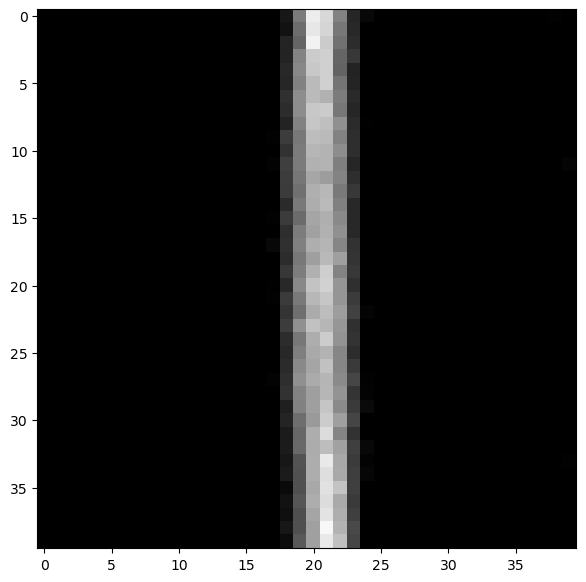

In [89]:
index = 65855
# xlim = (relevant.loc[index,'closest_x']-20,relevant.loc[index,'closest_x']+20)
# ylim = (relevant.loc[index,'central_point_brightening']-20,relevant.loc[index,'central_point_brightening']+20)
plt.imshow(small_image, clim=[200,400])
# plt.xlim(xlim)
# plt.ylim(ylim)
plt.show()

In [ ]:
1173